# **Практическая работа №2. Основные методы OpenCV (Часть №2). Базовые операции**

## **Импорты и вспомогательные функции**

In [42]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import requests

# cv2_imshow есть только в Google Colab; вне Colab используем замену с тем же поведением:
# значения обрезаются до [0, 255], приводятся к uint8, цветные — из BGR в RGB
try:
    from google.colab.patches import cv2_imshow
except ImportError:
    def cv2_imshow(img):
        a = np.clip(img, 0, 255).astype(np.uint8)
        plt.figure(figsize=(16, max(1.5, 16 * a.shape[0] / a.shape[1])))
        if a.ndim == 2:
            plt.imshow(a, cmap="gray", vmin=0, vmax=255)
        else:
            plt.imshow(cv.cvtColor(a, cv.COLOR_BGR2RGB))
        plt.axis("off")
        plt.show()


def show_images(images, titles, figsize=None, cmap=None):
    """Отображает несколько изображений в один ряд (BGR -> RGB для цветных)."""
    n = len(images)
    plt.figure(figsize=figsize or (6 * n, 5))
    for i, (img, title) in enumerate(zip(images, titles), 1):
        plt.subplot(1, n, i)
        if img.ndim == 2:
            plt.imshow(img, cmap=cmap or "gray", vmin=0, vmax=255)
        else:
            plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

## **Базовый уровень**

---

### **Задание №1. Напишите функцию, которая принимает на вход строку с ссылкой на изображение из сети Интернет и возвращает открытое изображение в OpenCV**

Тип: ndarray | размер: (2400, 3840, 3) | тип данных: uint8


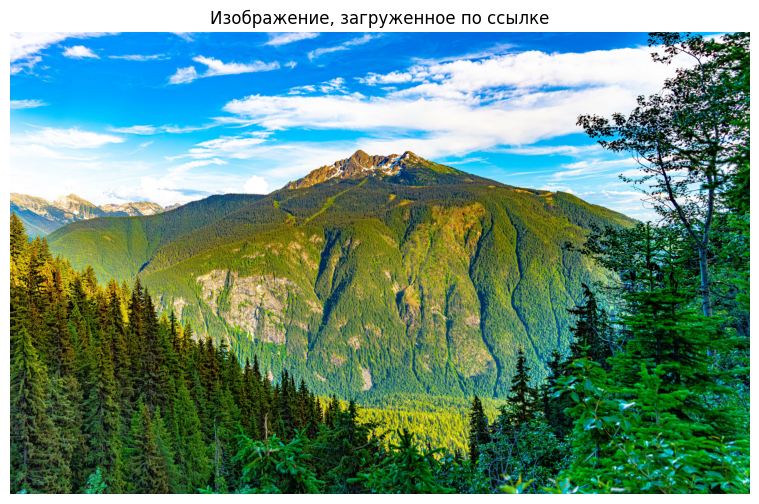

In [43]:
def load_image_from_url(url, flags=cv.IMREAD_COLOR, timeout=30):
    """Загружает изображение по ссылке из сети Интернет и возвращает его
    в виде массива NumPy в формате OpenCV (BGR, uint8)."""
    if not isinstance(url, str) or not url.startswith(("http://", "https://")):
        raise ValueError("Ожидается строка со ссылкой вида http(s)://...")

    # HTTP-запрос; User-Agent нужен, т.к. некоторые сайты не отдают файлы «ботам»
    response = requests.get(url, timeout=timeout, headers={"User-Agent": "Mozilla/5.0"})
    response.raise_for_status()                       # ошибка, если код ответа не 200

    # Байты ответа -> одномерный массив uint8 -> декодирование в изображение
    img_bytes = np.frombuffer(response.content, dtype=np.uint8)
    image = cv.imdecode(img_bytes, flags)
    if image is None:
        raise ValueError("Полученные по ссылке данные не удалось декодировать как изображение.")
    return image


IMAGE_URL = "https://images.wallpaperscraft.ru/image/single/gora_sklon_derevia_888129_3840x2400.jpg"

image = load_image_from_url(IMAGE_URL)
print("Тип:", type(image).__name__, "| размер:", image.shape, "| тип данных:", image.dtype)

plt.figure(figsize=(10, 6))
plt.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
plt.title("Изображение, загруженное по ссылке")
plt.axis("off")
plt.show()

---

### **Задание 2: Создание цветных градиентов**




**Задание:**

1. Создайте цветное изображение размером 512x512 пикселей.
2. Реализуйте вертикальный градиент от зеленого к синему цвету:
   - Сверху изображение должно быть полностью зеленым.
   - Снизу изображение должно быть насыщенного синего цвета.
   - Градиент должен плавно изменяться по вертикали.
3. Отобразите полученное изображение, убедившись в корректности градиента.

**Подсказки:**

- Используйте функции библиотеки NumPy для создания и заполнения массива изображения.
- Помните, что в OpenCV цветовое пространство BGR (Blue, Green, Red).



верх      строка   0: BGR = (0, 255, 0)
середина  строка 256: BGR = (128, 127, 0)
низ       строка 511: BGR = (255, 0, 0)


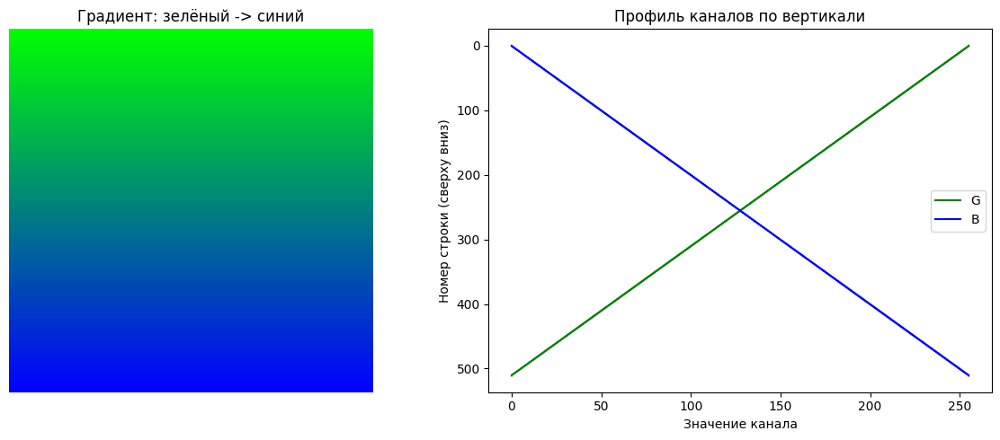

In [44]:
H, W = 512, 512

# Коэффициент t меняется от 0 (верхняя строка) до 1 (нижняя строка)
t = np.linspace(0.0, 1.0, H, dtype=np.float32).reshape(H, 1)

gradient = np.zeros((H, W, 3), dtype=np.uint8)       # порядок каналов в OpenCV: B, G, R
gradient[:, :, 0] = np.round(255 * t)                # B: 0 сверху -> 255 снизу
gradient[:, :, 1] = np.round(255 * (1 - t))          # G: 255 сверху -> 0 снизу
gradient[:, :, 2] = 0                                # R не используется

# Проверка корректности: значения (B, G, R) в верхней, средней и нижней строках
for name, row in (("верх", 0), ("середина", H // 2), ("низ", H - 1)):
    print(f"{name:9s} строка {row:3d}: BGR = {tuple(int(v) for v in gradient[row, 0])}")

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(cv.cvtColor(gradient, cv.COLOR_BGR2RGB))
ax[0].set_title("Градиент: зелёный -> синий")
ax[0].axis("off")
ax[1].plot(gradient[:, 0, 1], range(H), "g", label="G")
ax[1].plot(gradient[:, 0, 0], range(H), "b", label="B")
ax[1].invert_yaxis()
ax[1].set_xlabel("Значение канала")
ax[1].set_ylabel("Номер строки (сверху вниз)")
ax[1].set_title("Профиль каналов по вертикали")
ax[1].legend()
plt.tight_layout()
plt.show()

---

### **Задание №3. Рисование сложных фигур**



**Задание:**

1. Создайте черное изображение размером 800x600 пикселей.
2. Нарисуйте на изображении следующие фигуры:
   - Красный круг с центром в точке (400, 300) и радиусом 100 пикселей.
   - Синий квадрат со стороной 50 пикселей, вписанный в круг из предыдущего пункта.
   - Зеленый треугольник, вершины которого совпадают с тремя вершинами квадрата.
3. Добавьте текст "OpenCV" белого цвета внутри квадрата, используя шрифт, поддерживающий кириллицу.
4. Отобразите полученное изображение.

**Подсказки:**

- Используйте функции `cv.circle()`, `cv.rectangle()`, `cv.polylines()` для рисования фигур.
- Для задания координат треугольника вам потребуется вычислить позиции трех вершин квадрата.
- Функция `cv.putText()` поможет добавить текст на изображение.

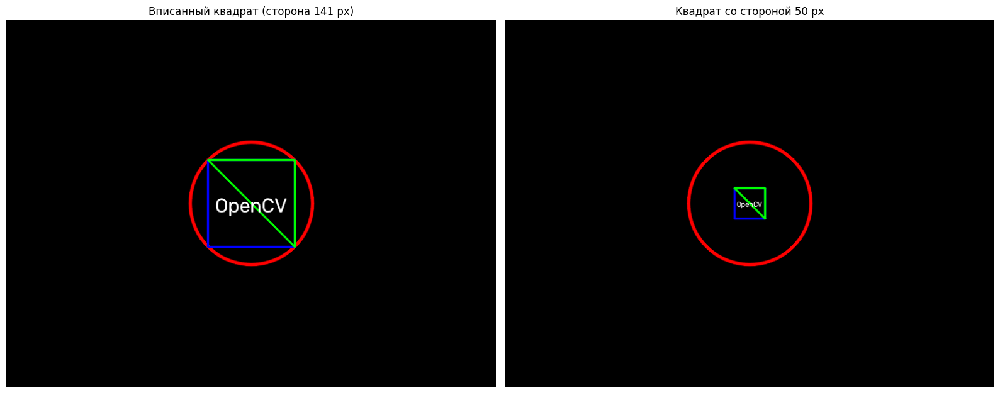

In [45]:
def draw_scene(square_side):
    """Чёрное изображение 800x600 с кругом, квадратом, треугольником и текстом."""
    img = np.zeros((600, 800, 3), dtype=np.uint8)       # высота 600, ширина 800
    center, radius = (400, 300), 100

    # 1) Красный круг (BGR: красный = (0, 0, 255))
    cv.circle(img, center, radius, (0, 0, 255), 3, cv.LINE_AA)

    # 2) Синий квадрат с центром в центре круга
    half = square_side / 2
    cx, cy = center
    tl = (round(cx - half), round(cy - half))    # верхний левый
    tr = (round(cx + half), round(cy - half))    # верхний правый
    br = (round(cx + half), round(cy + half))    # нижний правый
    bl = (round(cx - half), round(cy + half))    # нижний левый
    cv.rectangle(img, tl, br, (255, 0, 0), 2, cv.LINE_AA)

    # 3) Зелёный треугольник по трём вершинам квадрата
    triangle = np.array([tl, tr, br], dtype=np.int32).reshape((-1, 1, 2))
    cv.polylines(img, [triangle], True, (0, 255, 0), 2, cv.LINE_AA)

    # 4) Белый текст внутри квадрата. FONT_HERSHEY_COMPLEX поддерживает кириллицу.
    #    Масштаб подбираем так, чтобы текст занимал ~85% стороны квадрата.
    text, font, thickness = "OpenCV", cv.FONT_HERSHEY_COMPLEX, 1
    (tw, th), _ = cv.getTextSize(text, font, 1.0, thickness)
    scale = 0.85 * square_side / tw
    (tw, th), baseline = cv.getTextSize(text, font, scale, thickness)
    org = (round(cx - tw / 2), round(cy + th / 2))        # центрируем по горизонтали и вертикали
    cv.putText(img, text, org, font, scale, (255, 255, 255), thickness, cv.LINE_AA)
    return img


# Квадрат, вписанный в круг радиуса R, имеет сторону R·√2 (его диагональ = диаметр)
inscribed_side = 100 * np.sqrt(2)
scene_inscribed = draw_scene(inscribed_side)
scene_50 = draw_scene(50)

show_images([scene_inscribed, scene_50],
            [f"Вписанный квадрат (сторона {inscribed_side:.0f} px)", "Квадрат со стороной 50 px"],
            figsize=(16, 6.5))

> **Примечание.** В условии есть противоречие: квадрат, **вписанный** в круг радиусом 100 px, должен иметь сторону $100\sqrt{2} \approx 141$ px (его диагональ равна диаметру круга). Квадрат со стороной 50 px вписан в круг радиусом всего $25\sqrt{2} \approx 35$ px. Поэтому показаны оба варианта: слева — вписанный квадрат (вершины лежат на окружности), справа — квадрат со стороной 50 px с центром в центре круга. Треугольник в обоих случаях построен по трём вершинам квадрата.

---

### **Задание №4. Интерактивное выделение и преобразование области интереса**



**Задание:**

Реализуйте функцию, которая принимает на вход открытое изображение, а затем:
1. Позволяет пользователю указать область интереса (ROI) путем ввода координат верхнего левого и нижнего правого углов.
2. Вырезает указанную область из изображения.
3. Отражает эту область по вертикали и горизонтали.
4. Вставляет преобразованную область обратно в исходное изображение на исходное место.
5. Возвращает конечное изображение.

*Отобразите рядом изображение до и после обработки*

**Подсказки:**

- Используйте функции ввода `input()` для получения координат от пользователя.
- Для отражения воспользуйтесь функцией `cv.flip()` или реализуйте свой алгоритм с использованием срезов NumPy.




Размер изображения: ширина 3840, высота 2400.
Введите координаты области (x — по горизонтали, y — по вертикали).


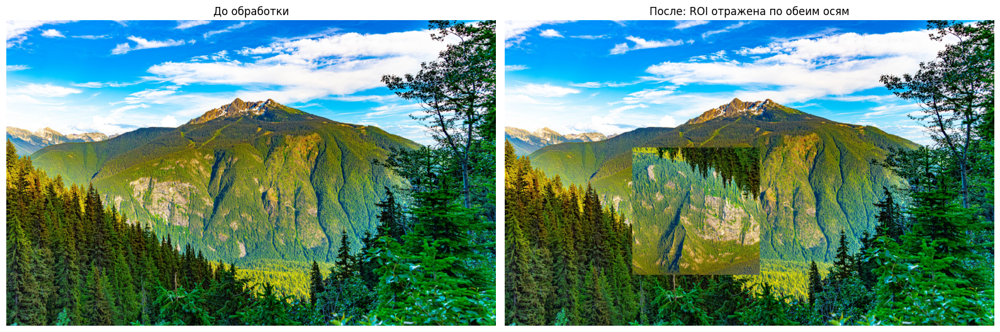

In [46]:
def read_int(prompt, low, high):
    """Запрашивает у пользователя целое число в диапазоне [low, high]."""
    while True:
        value = input(prompt).strip()
        try:
            number = int(value)
        except ValueError:
            print("  Нужно ввести целое число.")
            continue
        if low <= number <= high:
            return number
        print(f"  Число должно быть в диапазоне от {low} до {high}.")


def flip_roi(image):
    """Запрашивает координаты области интереса (ROI), отражает её
    по вертикали и горизонтали и вставляет на исходное место."""
    if not isinstance(image, np.ndarray) or image.size == 0 or image.ndim not in (2, 3):
        raise ValueError("Ожидается непустое изображение (массив NumPy).")

    h, w = image.shape[:2]
    print(f"Размер изображения: ширина {w}, высота {h}.")
    print("Введите координаты области (x — по горизонтали, y — по вертикали).")
    while True:
        x1 = read_int("x верхнего левого угла: ", 0, w - 1)
        y1 = read_int("y верхнего левого угла: ", 0, h - 1)
        x2 = read_int("x нижнего правого угла: ", 1, w)
        y2 = read_int("y нижнего правого угла: ", 1, h)
        if x2 > x1 and y2 > y1:
            break
        print("  Нижний правый угол должен быть правее и ниже верхнего левого. Повторите ввод.")

    result = image.copy()                     # исходное изображение не меняем
    roi = result[y1:y2, x1:x2]                # 1-2) вырезаем область срезом NumPy
    roi_flipped = cv.flip(roi, -1)            # 3) flipCode=-1: отражение по обеим осям
    result[y1:y2, x1:x2] = roi_flipped        # 4) вставляем обратно на то же место
    return result                             # 5) возвращаем результат


flipped = flip_roi(image)
show_images([image, flipped], ["До обработки", "После: ROI отражена по обеим осям"], figsize=(16, 5.5))

---

### **Задание 5: Реализация функции коррекции яркости и контраста**



**Задание:**

1. Напишите собственную функцию для изменения яркости и контраста изображения без использования `cv.convertScaleAbs()`.
2. Функция должна принимать параметры `alpha` (коэффициент контраста) и `beta` (сдвиг яркости).
3. Проверьте работу функции на цветном изображении с различными значениями `alpha` и `beta`.
4. Сравните результат вашей функции с результатом `cv.convertScaleAbs()`.

**Подсказки:**

- Убедитесь, что значения пикселей после преобразования остаются в диапазоне [0, 255].
- Для безопасного преобразования используйте функцию `np.clip()`.



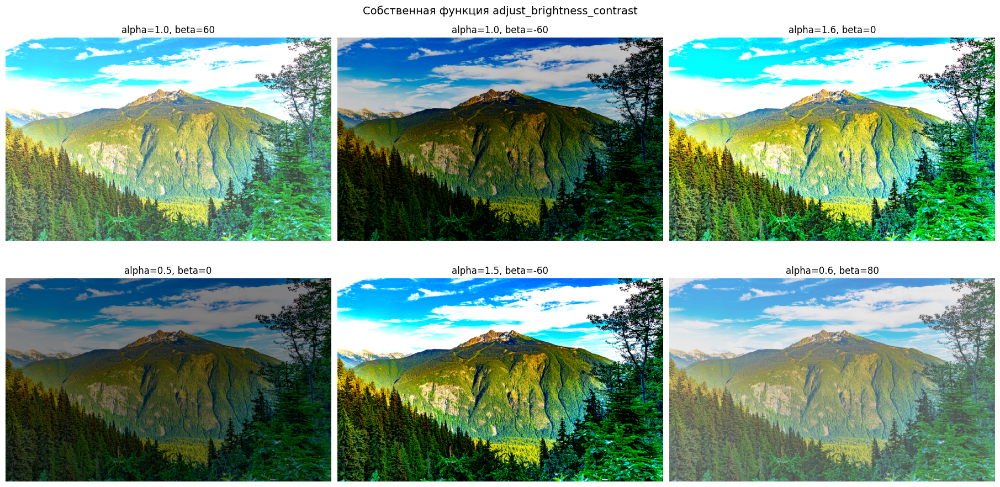

 alpha  beta  макс. разница  доля несовпадающих значений, %
   1.0    60              0                           0.000
   1.0   -60             60                          36.712
   1.6     0              0                           0.000
   0.5     0              0                           0.000
   1.5   -60             60                          29.631
   0.6    80              0                           0.000
   1.0  -150            150                          66.848
  -1.0   255              0                           0.000


In [47]:
def adjust_brightness_contrast(image, alpha=1.0, beta=0.0):
    """Линейная коррекция g(x) = alpha * f(x) + beta.
    alpha — коэффициент контраста, beta — сдвиг яркости.
    Вычисления во float32, чтобы не было переполнения uint8,
    затем округление и ограничение диапазоном [0, 255]."""
    if not isinstance(image, np.ndarray):
        raise TypeError("image должен быть массивом NumPy.")
    result = image.astype(np.float32) * alpha + beta
    result = np.clip(np.round(result), 0, 255)
    return result.astype(np.uint8)


params = [(1.0, 60), (1.0, -60), (1.6, 0), (0.5, 0), (1.5, -60), (0.6, 80)]

# Результаты собственной функции
# constrained_layout сам оставляет место под заголовки, чтобы они не налезали на изображения
fig, ax = plt.subplots(2, 3, figsize=(18, 9), constrained_layout=True)
for a, (alpha, beta) in zip(ax.ravel(), params):
    a.imshow(cv.cvtColor(adjust_brightness_contrast(image, alpha, beta), cv.COLOR_BGR2RGB))
    a.set_title(f"alpha={alpha}, beta={beta}", fontsize=12)
    a.axis("off")
fig.suptitle("Собственная функция adjust_brightness_contrast", fontsize=14)
plt.show()

# Сравнение с cv.convertScaleAbs
rows = []
for alpha, beta in params + [(1.0, -150), (-1.0, 255)]:
    mine = adjust_brightness_contrast(image, alpha, beta)
    ref = cv.convertScaleAbs(image, alpha=alpha, beta=beta)
    diff = cv.absdiff(mine, ref)
    rows.append({"alpha": alpha, "beta": beta,
                 "макс. разница": int(diff.max()),
                 "доля несовпадающих значений, %": round(100 * np.count_nonzero(diff) / diff.size, 3)})
print(pd.DataFrame(rows).to_string(index=False))

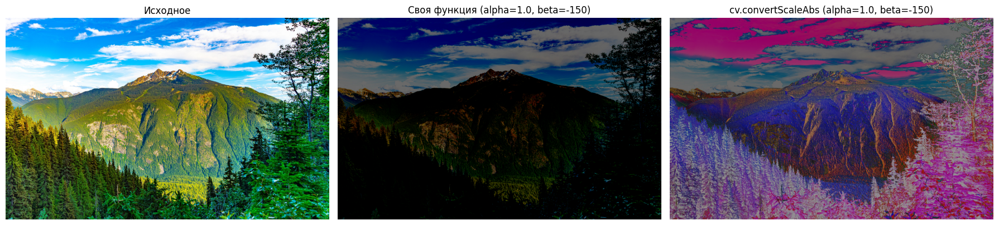

In [48]:
# Наглядно: при отрицательном результате convertScaleAbs берёт модуль,
# а собственная функция обрезает значения до 0
alpha, beta = 1.0, -150
mine = adjust_brightness_contrast(image, alpha, beta)
ref = cv.convertScaleAbs(image, alpha=alpha, beta=beta)
show_images([image, mine, ref],
            ["Исходное", f"Своя функция (alpha={alpha}, beta={beta})", f"cv.convertScaleAbs (alpha={alpha}, beta={beta})"],
            figsize=(18, 4.5))

**Вывод по заданию 5.** Собственная функция реализует ту же формулу, что и `cv.convertScaleAbs()`: $g(x) = \alpha \cdot f(x) + \beta$ с округлением и ограничением диапазона [0, 255]. Пока $\alpha f(x) + \beta \ge 0$, результаты совпадают. Различие появляется, когда выражение становится отрицательным: `cv.convertScaleAbs()` берёт **модуль** (Abs в названии), поэтому при сильном уменьшении яркости тёмные участки «отражаются» и снова становятся светлыми, а собственная функция корректно обрезает их до 0 (чёрный). Из-за модуля у `convertScaleAbs` работает инвертирование `alpha=-1, beta=255`: значение $255 - f(x)$ неотрицательно, поэтому обе функции дают одинаковый результат.

---

## **Повышенный уровень**

### **Комплексное задание №1: Анализ качества интерполяции изображений**



**Цель задания:**

- Закрепить понимание различных методов интерполяции и их влияния на качество изображений.
- Научиться применять метрики качества (например, MSE) для количественной оценки результатов обработки изображений.
- Практиковаться в написании эффективного и корректного кода для задач компьютерного зрения.

**Описание задания:**

- В данном задании вам предстоит исследовать влияние различных методов интерполяции на качество увеличенных изображений. Вы должны реализовать функцию для вычисления среднеквадратичной ошибки (MSE) между оригинальным изображением и его обработанной версией после уменьшения и последующего увеличения с использованием различных методов интерполяции.

**Требования к выполнению задания:**

1. **Реализация функции для вычисления MSE:**

   - Напишите функцию, которая принимает на вход два изображения одинакового размера и вычисляет среднеквадратичную ошибку (MSE) между ними. Формула для расчета MSE:

   $$
   \text{MSE} = \frac{1}{N} \sum_{i=1}^{N} (I_{\text{original}}(i) - I_{\text{processed}}(i))^2
   $$

   где:
   - $N$ — общее количество пикселей в изображении.
   - $I_{\text{original}}(i)$ и $I_{\text{processed}}(i)$ — значения интенсивности пикселя $i$ в исходном и обработанном изображениях соответственно.

2. **Сравнение методов интерполяции:**

   - Используйте следующие методы интерполяции при изменении размера изображения:
     - **Метод ближайшего соседа (Nearest Neighbor)**
     - **Билинейная интерполяция (Bilinear Interpolation)**
     - **Бикубическая интерполяция (Bicubic Interpolation)**

   - Для каждого метода выполните следующие шаги:
     - **а) Уменьшение изображения:**
       - Уменьшите исходное изображение по каждой оси в 2 и 4 раза (т.е. по площади в 4 и 16 раз соответственно) с использованием выбранного метода интерполяции.
     - **б) Увеличение изображения:**
       - Увеличьте полученное уменьшенное изображение обратно до исходного размера, используя тот же метод интерполяции.
     - **в) Вычисление MSE:**
       - Вычислите MSE между исходным изображением и восстановленным после увеличения.
   
   - Повторите эти шаги для каждого метода интерполяции и каждого коэффициента масштабирования (2 и 4 раза).

3. **Анализ и представление результатов:**

   - Представьте результаты в виде таблицы, где для каждого метода интерполяции и коэффициента масштабирования указано значение MSE.
   - Сравните полученные значения MSE между методами:
     - Какой метод дает наименьшую ошибку при разных коэффициентах масштабирования?
     - Как изменение коэффициента масштабирования влияет на качество восстановления изображения для каждого метода?
   - Сделайте выводы о том, какой метод интерполяции предпочтительнее использовать при увеличении изображений и почему.



**Дополнительные указания:**

- **Работа с цветными изображениями:**
  - Если вы работаете с цветными изображениями, вычисляйте MSE для каждого цветового канала (R, G, B) и затем усредняйте, либо преобразуйте изображение в оттенки серого перед обработкой.

- **Визуализация:**
  - Для наглядности вы можете дополнительно визуализировать исходные и восстановленные изображения, а также показать разницу между ними.
  - Используйте библиотеку **matplotlib** для отображения изображений в Colab.




**Пример структуры программы:**

- **Функция для вычисления MSE:**
  ```python
  def calculate_mse(original_image, processed_image):
      # Ваш код для вычисления MSE
  ```
  
- **Основная функция для сравнения методов:**
  ```python
  def compare_interpolation_methods(image_path):
      # Загрузка изображения
      # Применение методов интерполяции с разными коэффициентами масштабирования
      # Вычисление MSE для каждого случая
      # Представление и анализ результатов
  ```
  



**Ожидаемый результат:**

- Таблица с значениями MSE для каждого метода интерполяции и коэффициента масштабирования.
- Выводы по результатам анализа, например:

| Метод интерполяции    | Коэффициент масштабирования | MSE         |
|-----------------------|-----------------------------|-------------|
| Ближайший сосед       | Уменьшение в 2 раза         | Значение 1  |
| Ближайший сосед       | Уменьшение в 4 раза         | Значение 2  |
| Билинейная интерполяция | Уменьшение в 2 раза       | Значение 3  |
| ...                   | ...                         | ...         |

- Заключение о том, какой метод и при каком масштабировании сохраняет наилучшее качество изображения.

In [49]:
def calculate_mse(original_image, processed_image):
    """Среднеквадратичная ошибка между двумя изображениями одинакового размера.
    Для цветных изображений усреднение идёт по всем пикселям всех каналов —
    это то же самое, что посчитать MSE для каждого канала и усреднить."""
    if original_image.shape != processed_image.shape:
        raise ValueError(f"Размеры не совпадают: {original_image.shape} и {processed_image.shape}")
    # float64, чтобы разность и квадрат не переполнили uint8
    diff = original_image.astype(np.float64) - processed_image.astype(np.float64)
    return float(np.mean(diff ** 2))


METHODS = {
    "Ближайший сосед": cv.INTER_NEAREST,
    "Билинейная": cv.INTER_LINEAR,
    "Бикубическая": cv.INTER_CUBIC,
}
FACTORS = (2, 4)


def downscale_upscale(image, factor, interpolation):
    """Уменьшение в factor раз по каждой оси и увеличение обратно тем же методом."""
    h, w = image.shape[:2]
    small = cv.resize(image, (w // factor, h // factor), interpolation=interpolation)
    restored = cv.resize(small, (w, h), interpolation=interpolation)   # строго исходный размер
    return restored


def compare_interpolation_methods(image_or_path):
    """Сравнивает методы интерполяции по MSE. Принимает изображение (массив),
    путь к файлу или ссылку на изображение."""
    if isinstance(image_or_path, str):
        if image_or_path.startswith(("http://", "https://")):
            image = load_image_from_url(image_or_path)
        else:
            image = cv.imread(image_or_path, cv.IMREAD_COLOR)
            if image is None:
                raise FileNotFoundError(f"Не удалось прочитать {image_or_path}")
    else:
        image = image_or_path

    rows, restored_images = [], {}
    for name, method in METHODS.items():
        for factor in FACTORS:
            restored = downscale_upscale(image, factor, method)
            restored_images[(name, factor)] = restored
            rows.append({"Метод интерполяции": name,
                         "Коэффициент масштабирования": f"Уменьшение в {factor} раза",
                         "MSE": round(calculate_mse(image, restored), 2)})
    return pd.DataFrame(rows), restored_images


results, restored_images = compare_interpolation_methods(image)
print(results.to_string(index=False))

Метод интерполяции Коэффициент масштабирования     MSE
   Ближайший сосед         Уменьшение в 2 раза  460.77
   Ближайший сосед         Уменьшение в 4 раза 1173.38
        Билинейная         Уменьшение в 2 раза  226.27
        Билинейная         Уменьшение в 4 раза  489.54
      Бикубическая         Уменьшение в 2 раза  183.43
      Бикубическая         Уменьшение в 4 раза  580.07


Коэффициент масштабирования  Уменьшение в 2 раза  Уменьшение в 4 раза
Метод интерполяции                                                   
Ближайший сосед                           460.77              1173.38
Билинейная                                226.27               489.54
Бикубическая                              183.43               580.07


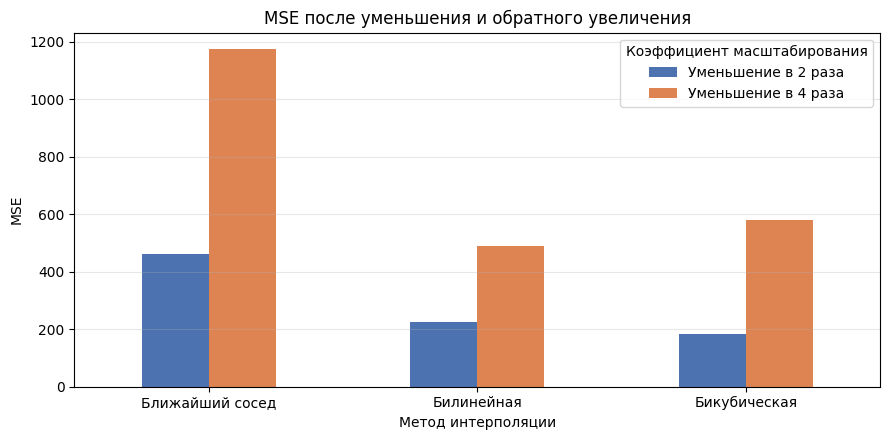

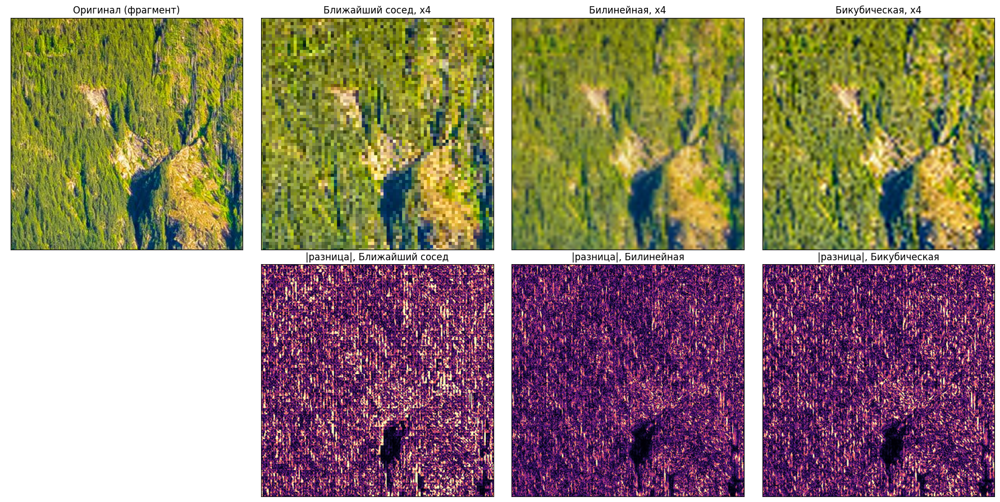

In [50]:
# Сводная таблица и диаграмма
pivot = results.pivot(index="Метод интерполяции", columns="Коэффициент масштабирования", values="MSE")
pivot = pivot.loc[list(METHODS)]
print(pivot.to_string())

pivot.plot(kind="bar", figsize=(9, 4.5), rot=0, color=["#4C72B0", "#DD8452"])
plt.ylabel("MSE")
plt.title("MSE после уменьшения и обратного увеличения")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Визуализация на фрагменте 300x300 (коэффициент 4) и карты ошибок
y0, x0, s = 1150, 1850, 300
crop = (slice(y0, y0 + s), slice(x0, x0 + s))
fig, ax = plt.subplots(2, 4, figsize=(18, 9))
ax[0, 0].imshow(cv.cvtColor(image[crop], cv.COLOR_BGR2RGB))
ax[0, 0].set_title("Оригинал (фрагмент)")
ax[1, 0].axis("off")
for j, name in enumerate(METHODS, start=1):
    rec = restored_images[(name, 4)]
    ax[0, j].imshow(cv.cvtColor(rec[crop], cv.COLOR_BGR2RGB))
    ax[0, j].set_title(f"{name}, x4")
    err = cv.cvtColor(cv.absdiff(image, rec)[crop], cv.COLOR_BGR2GRAY)
    ax[1, j].imshow(err, cmap="magma", vmin=0, vmax=80)
    ax[1, j].set_title(f"|разница|, {name}")
for a in ax.ravel():
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout()
plt.show()

In [51]:
# Дополнительно: уменьшение методом INTER_AREA (усреднение по площади),
# увеличение — исследуемыми методами. Показывает, какая часть ошибки
# возникает на этапе уменьшения.
rows = []
h, w = image.shape[:2]
for factor in FACTORS:
    small = cv.resize(image, (w // factor, h // factor), interpolation=cv.INTER_AREA)
    for name, method in METHODS.items():
        restored = cv.resize(small, (w, h), interpolation=method)
        rows.append({"Увеличение": name, "Коэффициент": factor,
                     "MSE": round(calculate_mse(image, restored), 2)})
area = pd.DataFrame(rows).pivot(index="Увеличение", columns="Коэффициент", values="MSE").loc[list(METHODS)]
area.columns = [f"Уменьшение в {c} раза (INTER_AREA)" for c in area.columns]
print(area.to_string())

                 Уменьшение в 2 раза (INTER_AREA)  Уменьшение в 4 раза (INTER_AREA)
Увеличение                                                                         
Ближайший сосед                            231.71                            513.46
Билинейная                                 226.27                            477.29
Бикубическая                               181.68                            423.49


### **Анализ результатов и выводы**

| Метод интерполяции | Уменьшение в 2 раза | Уменьшение в 4 раза |
|---|---|---|
| Ближайший сосед | 460.77 | 1173.38 |
| Билинейная | 226.27 | **489.54** |
| Бикубическая | **183.43** | 580.07 |

**Какой метод даёт наименьшую ошибку?**
- При уменьшении **в 2 раза** лучший результат у **бикубической** интерполяции (MSE ≈ 183), билинейная — ≈ 226, ближайший сосед — ≈ 461, то есть в 2,5 раза хуже бикубической.
- При уменьшении **в 4 раза** лучше всех **билинейная** (≈ 490), бикубическая — ≈ 580, ближайший сосед — ≈ 1173.

**Как влияет коэффициент масштабирования?** При переходе от 2 к 4 ошибка растёт у всех методов: у ближайшего соседа в ≈ 2,5 раза, у билинейной в ≈ 2,2 раза, у бикубической в ≈ 3,2 раза. При уменьшении в 4 раза остаётся лишь 1/16 пикселей, мелкие детали (отдельные деревья на склоне) теряются безвозвратно, и никакая интерполяция не может их восстановить. На картах ошибок видно, что вся ошибка сосредоточена на мелкой текстуре, а на однородных участках (тень) она близка к нулю.

**Почему бикубическая проигрывает при уменьшении в 4 раза.** Ошибка возникает на этапе **уменьшения**: при шаге 4 пикселя окно бикубической интерполяции охватывает лишь часть пикселей исходного блока 4×4, мелкие детали «перескакивают» (алиасинг), а бикубический метод, усиливающий резкость, эти искажения подчёркивает. Дополнительный эксперимент это подтверждает: если уменьшать методом `INTER_AREA` (усреднение по площади), а увеличивать исследуемыми методами, бикубическая интерполяция становится лучшей при обоих коэффициентах (≈ 182 и ≈ 423), а ближайший сосед остаётся худшим (≈ 232 и ≈ 513). При уменьшении ровно в 2 раза `INTER_LINEAR` усредняет блоки 2×2 так же, как `INTER_AREA`, поэтому для билинейной значение одинаковое — 226.27.

**Вывод.**
- Для **увеличения** изображений предпочтительна **бикубическая** интерполяция: она даёт наименьшую ошибку и визуально самый чёткий результат. Билинейная — компромисс между скоростью и качеством, картинка получается более мягкой.
- **Ближайший сосед** даёт наибольшую ошибку и «пикселизацию»; его стоит использовать, только когда нельзя создавать новые значения — например, при масштабировании масок сегментации и карт классов.
- Для **уменьшения** изображений лучше использовать `INTER_AREA`: качество итогового изображения определяется прежде всего тем, сколько информации сохранилось при уменьшении.

---

### **Комплексное задание №2: Создание HDR-подобного эффекта на обычном изображении**

#### **Описание задания:**

  - В этом задании вам необходимо разработать программу на Python с использованием библиотеки OpenCV, которая преобразует обычное изображение в изображение с HDR-подобным эффектом. Вы должны реализовать собственный метод объединения изображений с разной экспозицией, используя операции NumPy.


#### **Основные определения:**

1. **Экспозиция** — это количество света, которое попадает на светочувствительный элемент камеры (матрицу или пленку) во время съемки. Экспозиция определяется сочетанием трех параметров:

  - **Выдержка**: время, в течение которого затвор камеры остается открытым, позволяя свету попасть на матрицу.
  - **Диафрагма**: размер отверстия в объективе, через которое проходит свет; измеряется в числах f/стоп.
  - **Чувствительность ISO**: уровень чувствительности матрицы камеры к свету.

  > Правильная установка этих параметров позволяет получить изображение с оптимальной яркостью и контрастностью, отображая детали как в светлых, так и в темных областях.


2. **HDR (High Dynamic Range) изображение** — это изображение с расширенным динамическим диапазоном яркости. Динамический диапазон представляет разницу между самыми темными и самыми светлыми участками изображения. HDR-изображения позволяют отобразить детали во всех областях сцены, даже если контраст между тенями и уровнями светам очень велик.

- HDR-эффект достигается путем:

  - **Объединения нескольких изображений** одной и той же сцены, снятых с разными настройками экспозиции (недоэкспонированное, нормально экспонированное и переэкспонированное). Это позволяет захватить полный диапазон яркостей сцены.
  - **Применения специальных алгоритмов обработки**, которые расширяют динамический диапазон одного изображения, усиливая детали в тенях и светах.

  > Используя HDR, фотографы и специалисты по обработке изображений могут создавать богатые деталями и реалистичные изображения, близкие к тому, как человеческий глаз воспринимает мир.

#### **Цели:**

- Научиться работать с изображениями в OpenCV без использования готовых функций для смешивания изображений.
- Освоить базовые операции обработки изображений: изменение яркости, объединение изображений, повышение контрастности.
- Получить навыки создания эффектов с помощью операций NumPy.


#### **Требования к программе:**

1. **Загрузка изображения:**
   - Программа должна быть реализована в виде функции или набора функций, основная функция получает на вход исходное изображение, открытое заранее в OpenCV и возвращает обработанное изображение.

2. **Создание виртуальных экспозиций:**
   - На основе исходного изображения создать несколько версий изображения с разной экспозицией:
     - **Недоэкспонированное** изображение (темнее исходного).
     - **Правильно экспонированное** изображение (без изменений).
     - **Переэкспонированное** изображение (светлее исходного).
   - Для изменения экспозиции можно использовать простые операции изменения яркости:
     - Уменьшение или увеличение яркости путем умножения пикселей на коэффициент. Оптимальный коэффициент Вы выбираете сами.

3. **Объединение экспозиций:**
   - Используйте операции NumPy для объединения изображений.
   
    Для этого необходимо:
      - Поэлементно сложить изображения с разной экспозицией.
      - Нормализовать итоговое изображение, чтобы значения пикселей находились в диапазоне [0, 255].
      - Преобразовать тип данных изображения для предотвращения переполнения во время вычислений.

4. **Повышение контрастности:**
   - Применить метод выравнивания гистограммы для улучшения контрастности итогового изображения.
   - Для цветных изображений преобразовать их в цветовое пространство LAB и применить выравнивание гистограммы к яркостному каналу.

5. **Отображение результатов:**
   - Отобразить исходное и итоговое изображения рядом с помощью библиотеки `matplotlib`.
   - Убедиться в корректном отображении цветовых пространств при использовании `matplotlib` (преобразовать изображения из BGR в RGB).


#### **Подсказки и рекомендации:**

- **Изменение экспозиции:**
  - Можно использовать `cv.convertScaleAbs()` для корректного изменения яркости и преобразования типов данных.
  - Коэффициенты изменения яркости должны быть выбраны так, чтобы обеспечить заметное отличие между экспозициями.

- **Объединение изображений:**
  - Преобразовать изображения в формат `float32` перед суммированием, чтобы избежать переполнения.
  - После суммирования разделить итоговое изображение на количество объединяемых изображений для нормализации.
  - Использовать функцию `np.clip()` для ограничения значений пикселей в диапазоне [0, 255].
  - Преобразовать итоговое изображение обратно в формат `uint8`.


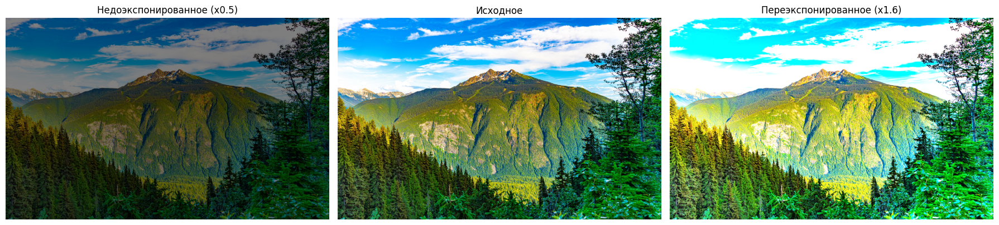

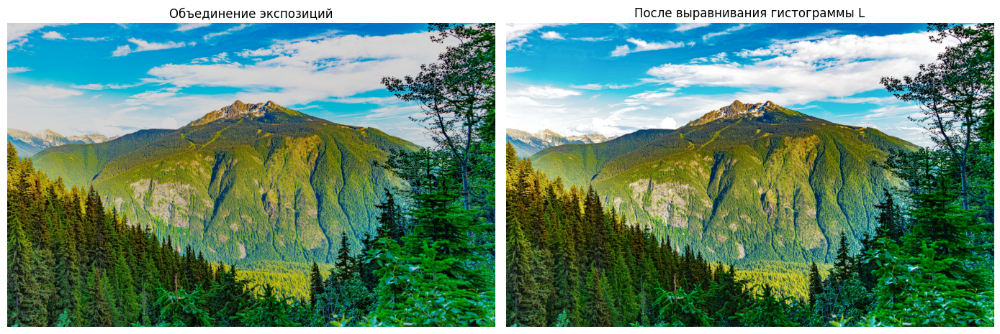

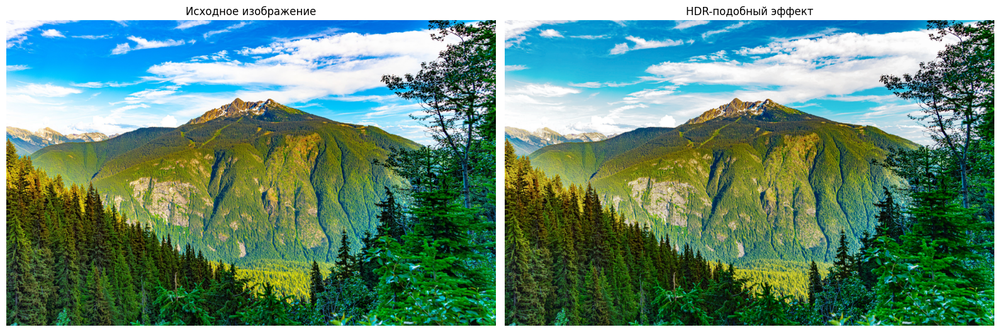

In [52]:
def create_exposures(image, under=0.5, over=1.6):
    """Виртуальные экспозиции: недоэкспонированное (темнее), исходное и
    переэкспонированное (светлее) изображение. Яркость меняется умножением
    на коэффициент; convertScaleAbs ограничивает результат диапазоном [0, 255]."""
    under_exposed = cv.convertScaleAbs(image, alpha=under, beta=0)
    normal = image.copy()
    over_exposed = cv.convertScaleAbs(image, alpha=over, beta=0)
    return [under_exposed, normal, over_exposed]


def merge_exposures(images):
    """Объединение экспозиций средствами NumPy:
    поэлементная сумма во float32 (без переполнения), деление на число
    изображений, ограничение [0, 255] и приведение обратно к uint8."""
    acc = np.zeros(images[0].shape, dtype=np.float32)
    for img in images:
        acc += img.astype(np.float32)
    acc /= len(images)
    return np.clip(acc, 0, 255).astype(np.uint8)


def equalize_lab(image):
    """Повышение контраста: выравнивание гистограммы канала яркости L в LAB."""
    l, a, b = cv.split(cv.cvtColor(image, cv.COLOR_BGR2LAB))
    l_eq = cv.equalizeHist(l)
    return cv.cvtColor(cv.merge((l_eq, a, b)), cv.COLOR_LAB2BGR)


def hdr_effect(image, under=0.5, over=1.6, visible=False):
    """Основная функция: принимает изображение, открытое в OpenCV (BGR, uint8),
    и возвращает изображение с HDR-подобным эффектом."""
    if not isinstance(image, np.ndarray) or image.ndim != 3 or image.shape[2] != 3:
        raise ValueError("Ожидается цветное изображение BGR (массив H x W x 3).")
    if image.dtype != np.uint8:
        raise TypeError("Ожидается изображение типа uint8.")

    exposures = create_exposures(image, under, over)
    merged = merge_exposures(exposures)
    result = equalize_lab(merged)

    if visible:
        show_images(exposures, [f"Недоэкспонированное (x{under})", "Исходное", f"Переэкспонированное (x{over})"],
                    figsize=(18, 4.5))
        show_images([merged, result], ["Объединение экспозиций", "После выравнивания гистограммы L"],
                    figsize=(14, 4.8))
    return result


hdr = hdr_effect(image, visible=True)

# Исходное и итоговое изображения рядом
show_images([image, hdr], ["Исходное изображение", "HDR-подобный эффект"], figsize=(16, 5.5))

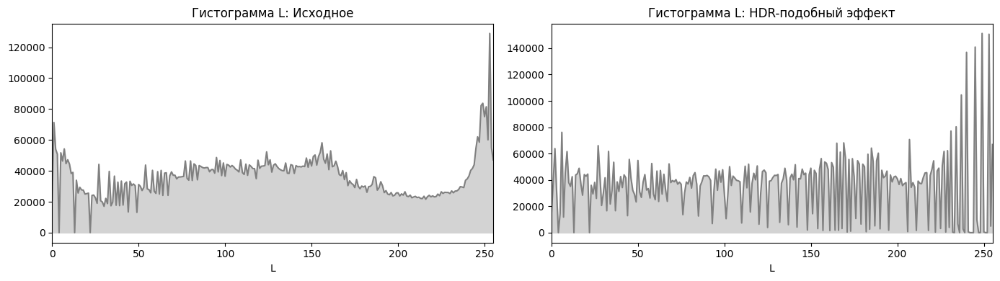

In [53]:
# Гистограммы яркости L до и после обработки
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, img, title in ((ax[0], image, "Исходное"), (ax[1], hdr, "HDR-подобный эффект")):
    l = cv.cvtColor(img, cv.COLOR_BGR2LAB)[:, :, 0]
    hist = cv.calcHist([l], [0], None, [256], [0, 256])
    a.plot(hist, color="gray")
    a.fill_between(range(256), hist.ravel(), color="lightgray")
    a.set_xlim([0, 255])
    a.set_title(f"Гистограмма L: {title}")
    a.set_xlabel("L")
plt.tight_layout()
plt.show()

### **Выводы**

- **Выбор коэффициентов.** Недоэкспонированная версия получена умножением на 0.5 (средняя яркость снизилась примерно с 111 до 55), переэкспонированная — на 1.6. При 1.6 в значение 255 уходят около 31% значений пикселей, при 2.0 — уже 39%, при 2.5 — 48%. Более сильное осветление «выжигает» небо и облака, а более слабое (1.3) мало отличается от исходника.
- **Объединение.** Сумма трёх экспозиций считается во `float32` (в `uint8` сумма переполнилась бы), затем делится на 3, ограничивается диапазоном [0, 255] и приводится к `uint8`. Тёмные и средние тона в среднем почти не меняются (0.5 + 1 + 1.6 ≈ 3), а в светлых участках переэкспонированная копия упирается в 255, поэтому светлые тона сжимаются — детали в облаках сохраняются лучше.
- **Повышение контраста.** Выравнивание гистограммы канала L (в пространстве LAB, чтобы не исказить цвета) растягивает яркости на весь диапазон: проработка леса в тенях и склонов горы стала заметнее, изображение выглядит контрастнее и «ярче», как типичное HDR-фото.
- **Ограничение метода.** `cv.equalizeHist()` работает глобально: самые светлые участки (небо, облака) уходят к максимуму яркости — это видно по пикам у 255 на гистограмме. Более мягкий результат дал бы адаптивный метод CLAHE. Кроме того, все «экспозиции» получены из одного кадра, поэтому информации, которой не было в исходнике (например, в полностью пересвеченных участках), такой метод добавить не может — это HDR-подобный эффект, а не настоящий HDR.

---

### **Комплексное задание №3: Генерация и модификация растровых изображений с использованием графических шаблонов**

#### Пункт №3.1.

**Создайте полностью черное растровое изображение с размерностью (1920, 1080, 3)**

In [54]:
canvas = np.zeros((1920, 1080, 3), dtype=np.uint8)
print("Размерность:", canvas.shape, "| тип:", canvas.dtype)
print(f"По соглашению NumPy/OpenCV это {canvas.shape[0]} строк (высота) и {canvas.shape[1]} столбцов (ширина).")

Размерность: (1920, 1080, 3) | тип: uint8
По соглашению NumPy/OpenCV это 1920 строк (высота) и 1080 столбцов (ширина).


#### Пункт №3.2.

**Напишите функцию, которая принимает на вход изображение и целое число n. После чего функция возвращает изображение с числом n графических объектов из линий в верхней части (выше половины высоты).**

 Графические объекты находятся в случайных местах и выглядят следующим образом:

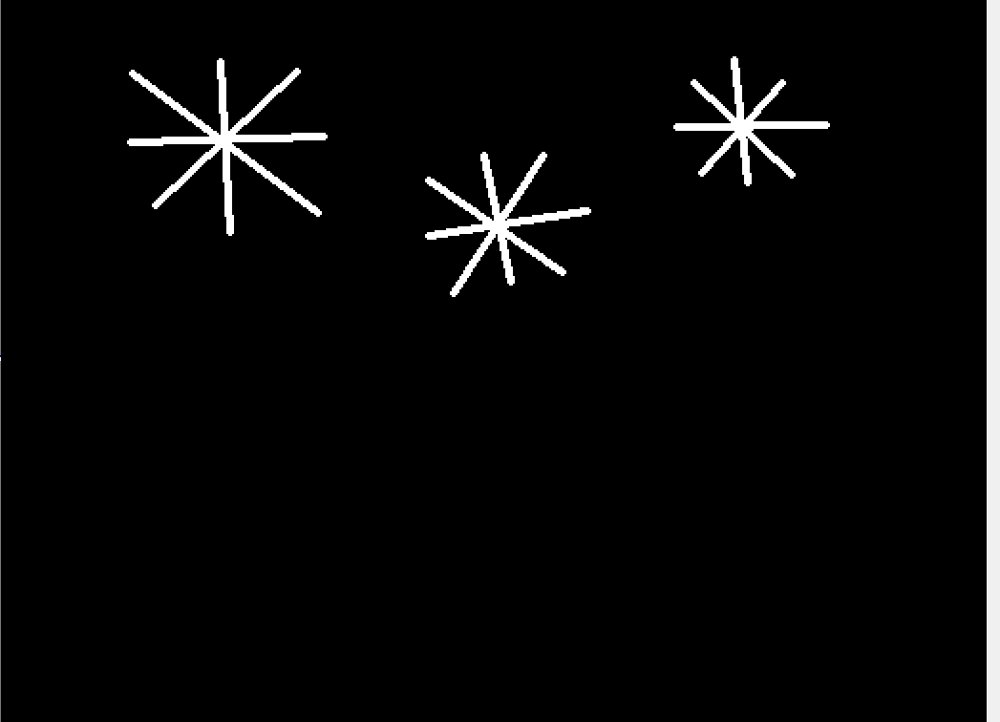

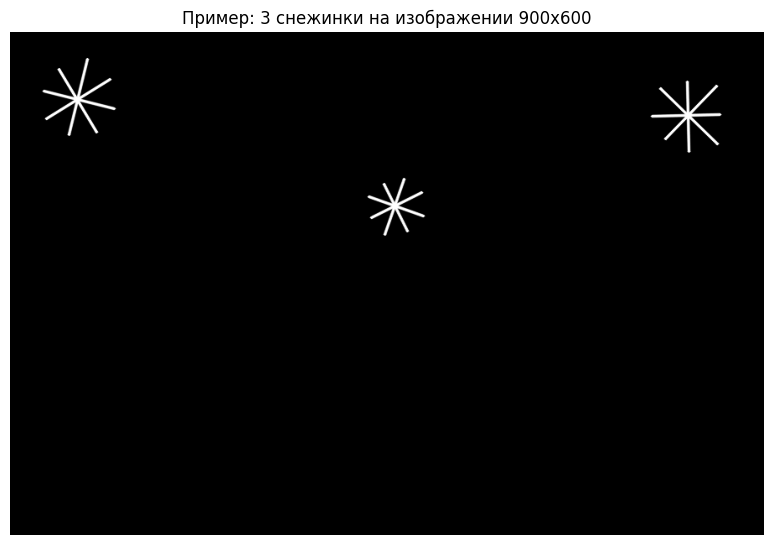

In [55]:
def _boxes_overlap(a, b):
    """Пересекаются ли прямоугольники (x1, y1, x2, y2)."""
    return not (a[2] <= b[0] or b[2] <= a[0] or a[3] <= b[1] or b[3] <= a[1])


def _place_objects(n, sample_box, rng, boxes=None, max_tries=300):
    """Случайно размещает n объектов, по возможности без наложений.
    sample_box() возвращает (параметры объекта, ограничивающий прямоугольник).
    boxes — список уже занятых областей; новые области добавляются в него,
    поэтому один список можно передавать в несколько функций рисования."""
    placed = []
    boxes = [] if boxes is None else boxes
    for _ in range(n):
        for _ in range(max_tries):
            params, box = sample_box()
            if all(not _boxes_overlap(box, b) for b in boxes):
                break                     # нашли место без наложения
        placed.append(params)             # если места нет — допускаем наложение
        boxes.append(box)
    return placed


def draw_snowflakes(image, n, color=(255, 255, 255), seed=None):
    """Возвращает изображение с n «снежинками» из линий в верхней части
    (целиком выше половины высоты)."""
    if not isinstance(n, (int, np.integer)) or n < 0:
        raise ValueError("n должно быть неотрицательным целым числом.")
    result = image.copy()
    h, w = result.shape[:2]
    rng = np.random.default_rng(seed)
    r_min, r_max = int(0.04 * min(h, w)), int(0.09 * min(h, w))

    def sample():
        r = int(rng.integers(r_min, r_max + 1))
        x = int(rng.integers(r, w - r))
        y = int(rng.integers(r, h // 2 - r))          # нижний край снежинки выше h/2
        return (x, y, r), (x - r, y - r, x + r, y + r)

    for x, y, r in _place_objects(n, sample, rng):
        base = rng.uniform(0, np.pi / 4)               # случайный поворот
        thickness = max(2, r // 18)
        for k in range(4):                             # 4 линии через центр = 8 лучей
            angle = base + k * np.pi / 4
            l1, l2 = r * rng.uniform(0.75, 1.0), r * rng.uniform(0.75, 1.0)
            p1 = (round(x + l1 * np.cos(angle)), round(y + l1 * np.sin(angle)))
            p2 = (round(x - l2 * np.cos(angle)), round(y - l2 * np.sin(angle)))
            cv.line(result, p1, p2, color, thickness, cv.LINE_AA)
    return result


demo = draw_snowflakes(np.zeros((600, 900, 3), np.uint8), 3, seed=1)
show_images([demo], ["Пример: 3 снежинки на изображении 900x600"], figsize=(8, 5.5))

#### Пункт №3.3

**Напишите функцию, которая принимает на вход изображение и целое число n. После чего функция возвращает изображение с числом n графических объектов из кругов в нижней части.**

Графические объекты находятся в случайных местах и выглядят следующим образом:

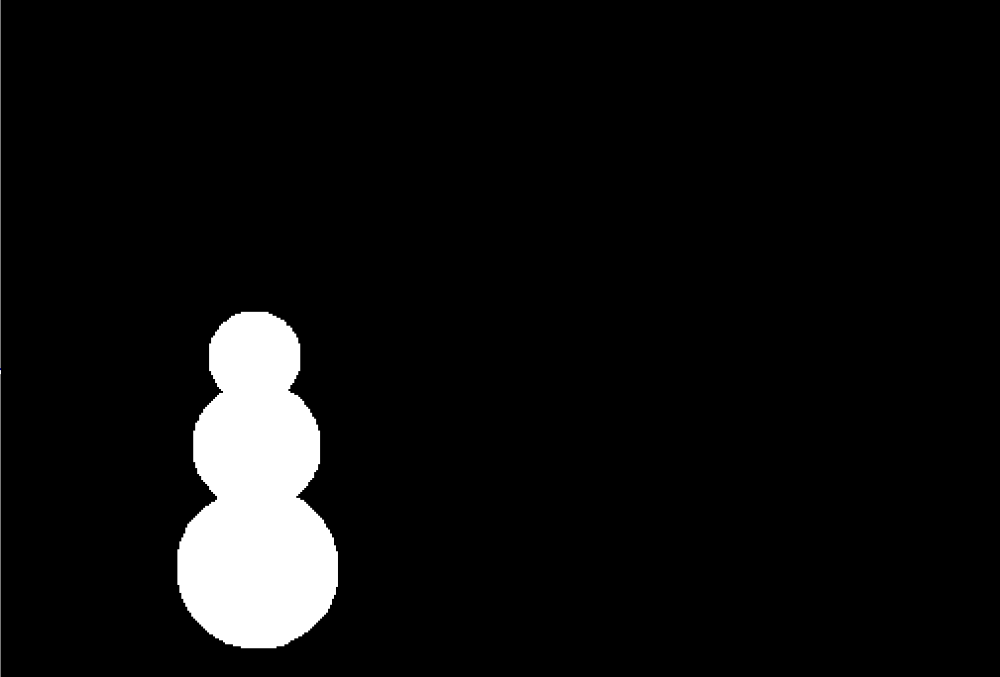

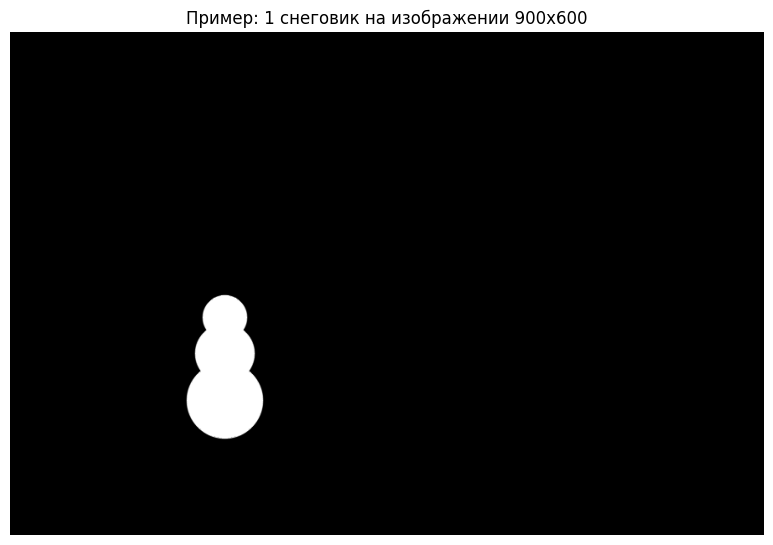

In [56]:
def draw_snowmen(image, n, color=(255, 255, 255), seed=None, avoid=None, y_max=None):
    """Возвращает изображение с n «снеговиками» из кругов в нижней части
    (целиком ниже половины высоты).
    avoid — необязательный список занятых областей (чтобы объекты не накладывались),
    y_max — необязательная нижняя граница размещения (по умолчанию — низ изображения)."""
    if not isinstance(n, (int, np.integer)) or n < 0:
        raise ValueError("n должно быть неотрицательным целым числом.")
    result = image.copy()
    h, w = result.shape[:2]
    rng = np.random.default_rng(seed)
    r_min, r_max = int(0.05 * min(h, w)), int(0.08 * min(h, w))
    bottom = h if y_max is None else int(y_max)

    def sample():
        r1 = int(rng.integers(r_min, r_max + 1))           # нижний шар
        r2, r3 = round(0.78 * r1), round(0.57 * r1)       # средний и голова
        total = 2 * r1 + 2 * r2 + 2 * r3 - round(0.3 * (r1 + r2) + 0.3 * (r2 + r3))
        x = int(rng.integers(r1, w - r1))
        y_bottom = int(rng.integers(h // 2 + total, bottom))   # нижняя точка снеговика
        return (x, y_bottom, r1, r2, r3), (x - r1, y_bottom - total, x + r1, y_bottom)

    for x, y_bottom, r1, r2, r3 in _place_objects(n, sample, rng, avoid):
        c1 = y_bottom - r1                                 # центр нижнего шара
        c2 = c1 - r1 - r2 + round(0.3 * (r1 + r2))         # шары немного перекрываются
        c3 = c2 - r2 - r3 + round(0.3 * (r2 + r3))
        for cy, r in ((c1, r1), (c2, r2), (c3, r3)):
            cv.circle(result, (x, cy), r, color, -1, cv.LINE_AA)   # -1 — заливка
    return result


demo = draw_snowmen(np.zeros((600, 900, 3), np.uint8), 1, seed=2)
show_images([demo], ["Пример: 1 снеговик на изображении 900x600"], figsize=(8, 5.5))

#### Пункт №3.4.

**Напишите функцию, которая принимает на вход изображение и целое число n. После чего функция возвращает изображение с числом n графических объектов из полигонов в нижней части.**

Графические объекты находятся в случайных местах и выглядят следующим образом:

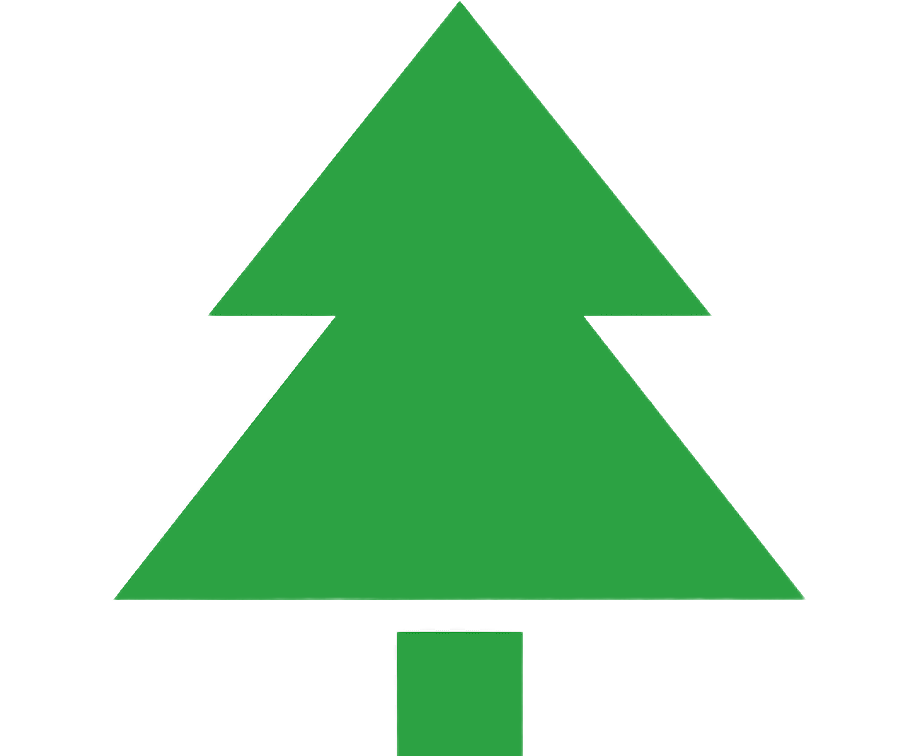

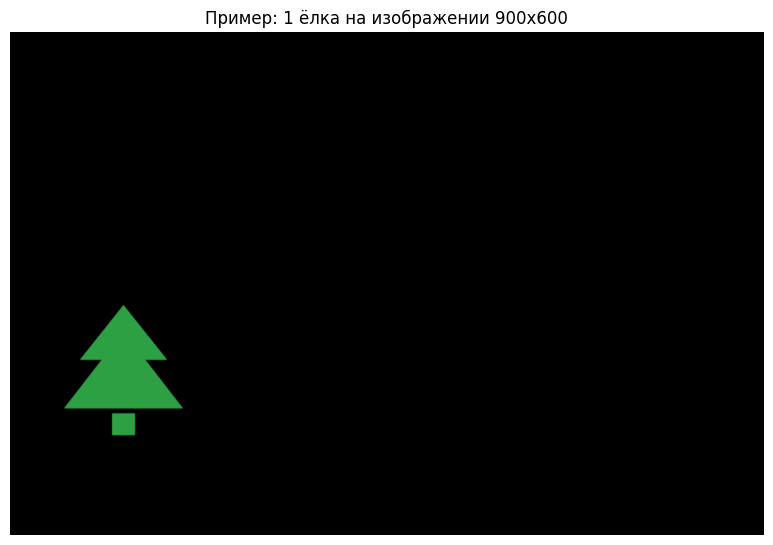

In [57]:
# Контур ёлки в относительных координатах (центр по x = 0, верхушка y = 0, высота 1)
TREE_OUTLINE = np.array([
    (0.000, 0.000),                    # верхушка
    (0.331, 0.417), (0.165, 0.417),    # правый выступ верхнего яруса
    (0.456, 0.794), (-0.456, 0.794),   # основание нижнего яруса
    (-0.165, 0.417), (-0.333, 0.417),  # левый выступ верхнего яруса
], dtype=np.float32)
TREE_TRUNK = np.array([(-0.083, 0.836), (0.082, 0.836), (0.082, 1.0), (-0.083, 1.0)], dtype=np.float32)


def draw_trees(image, n, color=(68, 160, 46), seed=None, avoid=None, y_max=None):
    """Возвращает изображение с n «ёлками» из полигонов в нижней части
    (целиком ниже половины высоты).
    avoid — необязательный список занятых областей (чтобы объекты не накладывались),
    y_max — необязательная нижняя граница размещения (по умолчанию — низ изображения)."""
    if not isinstance(n, (int, np.integer)) or n < 0:
        raise ValueError("n должно быть неотрицательным целым числом.")
    result = image.copy()
    h, w = result.shape[:2]
    rng = np.random.default_rng(seed)
    s_min, s_max = int(0.15 * min(h, w)), int(0.28 * min(h, w))   # высота ёлки
    bottom = h if y_max is None else int(y_max)

    def sample():
        size = int(rng.integers(s_min, s_max + 1))
        half_w = int(np.ceil(0.456 * size))
        x = int(rng.integers(half_w, w - half_w))
        y_top = int(rng.integers(h // 2, bottom - size))  # верхушка ниже h/2
        return (x, y_top, size), (x - half_w, y_top, x + half_w, y_top + size)

    for x, y_top, size in _place_objects(n, sample, rng, avoid):
        offset = np.array([x, y_top], dtype=np.float32)
        crown = np.round(TREE_OUTLINE * size + offset).astype(np.int32)
        trunk = np.round(TREE_TRUNK * size + offset).astype(np.int32)
        cv.fillPoly(result, [crown, trunk], color, cv.LINE_AA)   # два залитых полигона
    return result


demo = draw_trees(np.zeros((600, 900, 3), np.uint8), 1, seed=3)
show_images([demo], ["Пример: 1 ёлка на изображении 900x600"], figsize=(8, 5.5))

#### Пункт №3.5

**Напишите функцию, которая принимает на вход изображение и строку. После чего функция возвращает изображение с наложенным на него текстом из строки.**

**Текст должен располагаться в нижней четверти изображения и выровнен по середине**

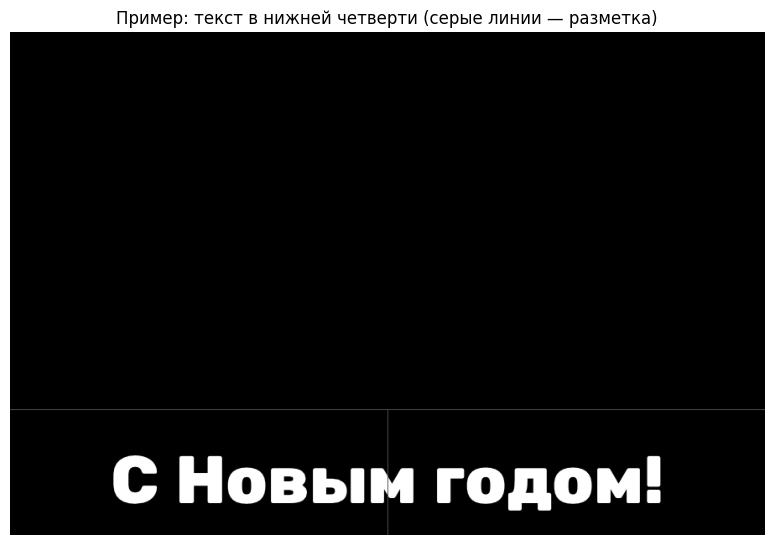

In [58]:
def put_text_bottom(image, text, color=(255, 255, 255), font=cv.FONT_HERSHEY_COMPLEX, thickness=None):
    """Возвращает изображение с текстом в нижней четверти, выровненным по середине.
    FONT_HERSHEY_COMPLEX поддерживает кириллицу. Размер шрифта подбирается так,
    чтобы текст занимал до 85% ширины и до 50% высоты нижней четверти."""
    if not isinstance(text, str) or not text:
        raise ValueError("text должен быть непустой строкой.")
    result = image.copy()
    h, w = result.shape[:2]
    quarter_top, quarter_h = h - h // 4, h // 4          # нижняя четверть: y от 3h/4 до h

    thickness = thickness or max(1, w // 400)
    (tw, th), _ = cv.getTextSize(text, font, 1.0, thickness)
    scale = min(0.85 * w / tw, 0.5 * quarter_h / th)
    thickness = max(thickness, round(scale))
    (tw, th), baseline = cv.getTextSize(text, font, scale, thickness)

    x = (w - tw) // 2                                    # по центру по горизонтали
    y = quarter_top + (quarter_h + th) // 2              # по центру нижней четверти
    cv.putText(result, text, (x, y), font, scale, color, thickness, cv.LINE_AA)
    return result


demo = put_text_bottom(np.zeros((600, 900, 3), np.uint8), "С Новым годом!")
demo_lines = demo.copy()
cv.line(demo_lines, (0, 450), (900, 450), (80, 80, 80), 1)      # граница нижней четверти
cv.line(demo_lines, (450, 450), (450, 600), (80, 80, 80), 1)    # вертикальная середина
show_images([demo_lines], ["Пример: текст в нижней четверти (серые линии — разметка)"], figsize=(8, 5.5))

#### Пункт №3.6

**Примените каждую из этих функций к изображению, созданному в пункте 4.1.**

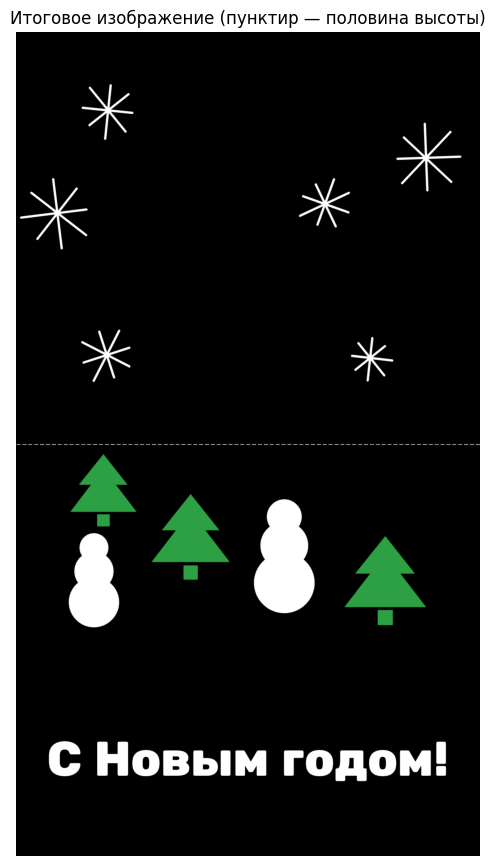

In [59]:
# Применяем функции к изображению из пункта 3.1 (в условии опечатка: «4.1»).
# Снеговики и ёлки получают общий список занятых областей, чтобы не накладываться,
# и размещаются выше нижней четверти, где будет текст.
occupied = []
text_top = canvas.shape[0] - canvas.shape[0] // 4

scene = draw_snowflakes(canvas, 6, seed=10)
scene = draw_snowmen(scene, 2, seed=11, avoid=occupied, y_max=text_top)
scene = draw_trees(scene, 3, seed=12, avoid=occupied, y_max=text_top)
scene = put_text_bottom(scene, "С Новым годом!")

cv.imwrite("complex3_scene.png", scene)

plt.figure(figsize=(6, 10.7))
plt.imshow(cv.cvtColor(scene, cv.COLOR_BGR2RGB))
plt.axhline(scene.shape[0] / 2, color="gray", lw=0.8, ls="--")   # половина высоты для проверки
plt.title("Итоговое изображение (пунктир — половина высоты)")
plt.axis("off")
plt.show()

---

### **Комплексное задание №4: Работа с данными радиолокационной съемки (SAR)**

#### **Краткая теория:**

Синтетическая апертурная радиолокация (SAR) — это технология, используемая для получения высококачественных радарных изображений земной поверхности. В отличие от традиционных радаров, которые полагаются на передачу и прием радиосигналов, SAR использует активную систему, генерирующую собственные радиосигналы и обрабатывающую их отражения от поверхности для создания изображения.

##### **Принцип работы SAR**

SAR анализирует время отклика радиоволн, отраженных от поверхности Земли. Радиоволны, испускаемые системой, имеют определенные длину волны и частоту. Когда эти волны достигают поверхности, часть из них отражается обратно к радару. Отражения происходят от различных объектов, таких как здания, леса, водные объекты и даже небольшие изменения рельефа.

##### **Каналы SAR**

SAR изображения содержат каналы HH и HV, которые представляют различные комбинации направления падающей и рассеиваемой энергии радиоволн:

- **Канал HH (горизонтально-горизонтальная поляризация)**: Используется для улучшения разрешающей способности и детализации объектов на изображении, особенно для плотных структур и материалов с границами и разделениями.

- **Канал HV (горизонтально-вертикальная поляризация)**: Применяется для выявления изменений в состоянии поверхности, таких как уровень воды в реках, засухи, обледенение и т. д. Он также дополняет информацию канала HH, предоставляя данные о рассеивающих свойствах поверхности.

##### **Комбинация каналов**

Каналы HH и HV могут быть объединены для создания композитных изображений, которые обеспечивают лучшую видимость и возможность анализа объектов и изменений на поверхности Земли. Это позволяет получать полезные данные о структурах, влажности, границах и других характеристиках поверхности.

##### **Применение SAR**

SAR изображения находят применение в различных областях:

- **Геология**: Изучение геологических структур, обнаружение нефтяных и газовых месторождений, оценка движения земной коры.
- **Астрономия**: Исследование поверхности планет и спутников, обнаружение и измерение астероидов и комет.
- **Экология**: Отслеживание изменений в растительности, выявление лесных пожаров, контроль использования земли.
- **Оборона**: Обнаружение и идентификация целей на земле или воде, независимо от условий освещения.

#### **Пункт 4.1. Загрузите изображение и откройте его:**




Ссылка на изображение: https://cloud.mail.ru/public/HEvc/aY7eMhHor

Используя библиотеку tifffile:

In [60]:
import tifffile as tiff

img = tiff.imread('S1B_EW_GRDM_1SDH_20210924T023033_20210924T023137_028834_0370F2_8BD8.tif') # Возвращается также как и в OpenCV массив Numpy,
                                   # далее работаете с методами из OpenCV как обычно

In [61]:
# Снимок очень большой (14958 x 1422), поэтому для вывода на экран
# используем уменьшенную копию: берём каждый 4-й пиксель (без интерполяции,
# чтобы не появлялись новые значения)
def preview(a, step=4):
    return a[::step, ::step]

print("Изображение загружено:", img.shape, img.dtype)

Изображение загружено: (1422, 14958, 4) uint16


#### **Пункт 4.2. Проанализируйте изображение**

Выведите тип изображения:

In [62]:
print("Тип объекта:", type(img))
print("Тип данных пикселей:", img.dtype)

Тип объекта: <class 'numpy.ndarray'>
Тип данных пикселей: uint16


Выведите его размерность:

In [63]:
print("Размерность:", img.shape)
h, w, n_channels = img.shape
print(f"Высота: {h}, ширина: {w}, число каналов: {n_channels}")
for c in range(n_channels):
    ch = img[:, :, c]
    print(f"Канал {c + 1}: min = {ch.min()}, max = {ch.max()}, "
          f"уникальных значений = {len(np.unique(ch))}, нулей = {100 * np.mean(ch == 0):.1f}%")

Размерность: (1422, 14958, 4)
Высота: 1422, ширина: 14958, число каналов: 4
Канал 1: min = 0, max = 171, уникальных значений = 3, нулей = 73.7%
Канал 2: min = 0, max = 250, уникальных значений = 7, нулей = 48.9%
Канал 3: min = 0, max = 255, уникальных значений = 5, нулей = 69.2%
Канал 4: min = 0, max = 255, уникальных значений = 2, нулей = 48.9%


Отобразите отдельно каждый канал, используя метод cv2_imshow():

Канал 1 (уменьшено в 4 раза для отображения):


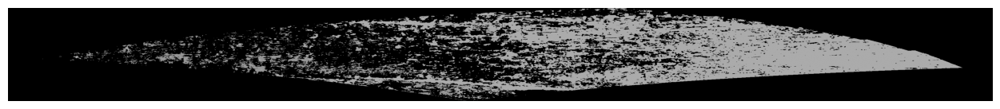

Канал 2 (уменьшено в 4 раза для отображения):


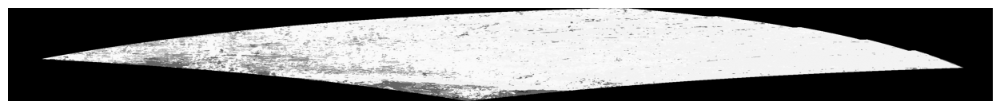

Канал 3 (уменьшено в 4 раза для отображения):


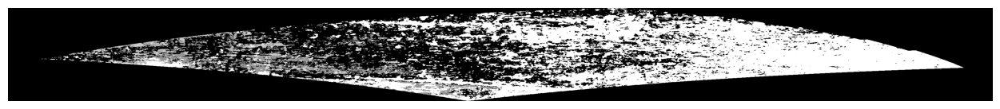

Канал 4 (уменьшено в 4 раза для отображения):


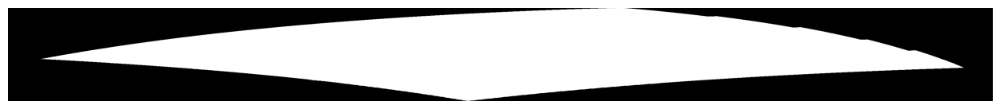

In [64]:
for c in range(img.shape[2]):
    print(f"Канал {c + 1} (уменьшено в 4 раза для отображения):")
    cv2_imshow(preview(img[:, :, c]))

Отобразите отдельно каждый канал, используя matplotlib:

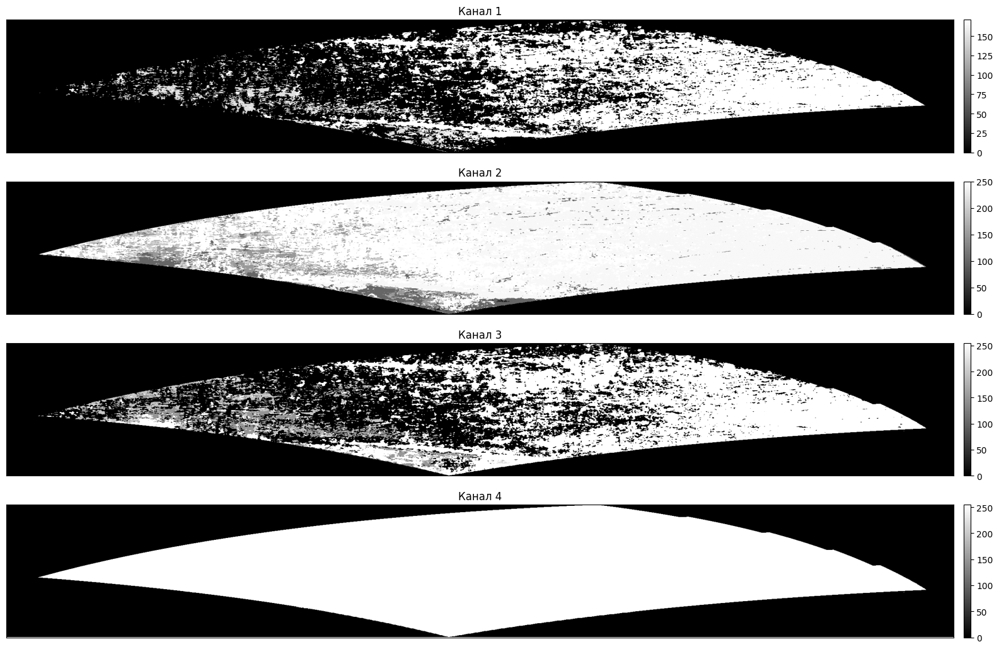

In [65]:
fig, ax = plt.subplots(img.shape[2], 1, figsize=(16, 2.6 * img.shape[2]))
for c in range(img.shape[2]):
    im = ax[c].imshow(preview(img[:, :, c]), cmap="gray", aspect="auto")
    ax[c].set_title(f"Канал {c + 1}")
    ax[c].set_xticks([]); ax[c].set_yticks([])
    fig.colorbar(im, ax=ax[c], fraction=0.02, pad=0.01)
plt.tight_layout()
plt.show()

Сделайте вывод:

- Изображение — массив NumPy типа `uint16` размерностью **(1422, 14958, 4)**: 1422 строки, 14958 столбцов и **4 канала**. Хотя тип 16-битный, значения лежат только в диапазоне 0–255.
- **Канал 4 — маска области съёмки**: в нём всего два значения, 0 (за пределами полосы) и 255 (внутри неё). Данные занимают около половины растра, остальное — нули (нет данных).
- **Каналы 1–3 содержат всего 3–7 различных значений** каждый (включая 0), а в области данных их сочетания дают всего 6 цветов. Значит, это не непрерывные значения обратного рассеяния HH/HV, а уже **раскрашенная тематическая (классифицированная) карта**, построенная по снимку Sentinel-1: однородные области одного класса чередуются с областями других классов.
- Файл — GeoTIFF в географических координатах WGS 84 с привязкой примерно к 82–87° с. ш. Вблизи полюса градус долготы намного короче градуса широты, поэтому в широтно-долготной сетке полоса съёмки сильно растянута по горизонтали и имеет вид узкого «ромба».
- `cv2_imshow` ограничивает значения диапазоном 0–255 и приводит их к `uint8`, поэтому здесь каналы отображаются корректно. `matplotlib` автоматически растягивает диапазон каждого канала. На обоих выводах видно, что каналы 1 и 3 почти бинарные (чёрное/белое), а в канале 2 больше градаций.
- Большая доля нулей вне полосы съёмки будет влиять на нормализацию и выравнивание гистограммы — это нужно учитывать на следующих шагах.

Постройте гистограмму изображения, используя функцию img2hist() из теоретических материалов:

--- Канал 1 ---
Среднее значение уровня серого: 44.39
Минимум: 0
Максимум: 171


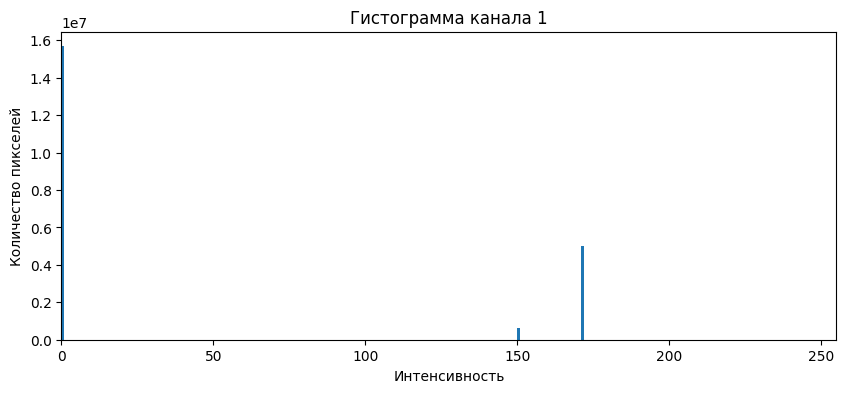

--- Канал 2 ---
Среднее значение уровня серого: 118.69
Минимум: 0
Максимум: 250


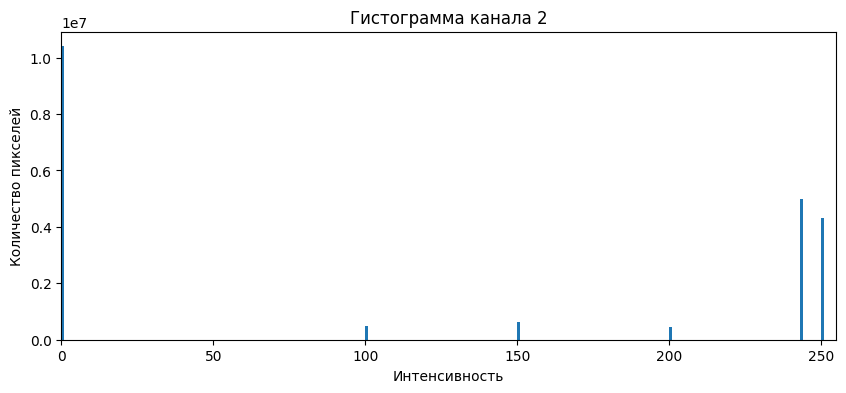

--- Канал 3 ---
Среднее значение уровня серого: 74.27
Минимум: 0
Максимум: 255


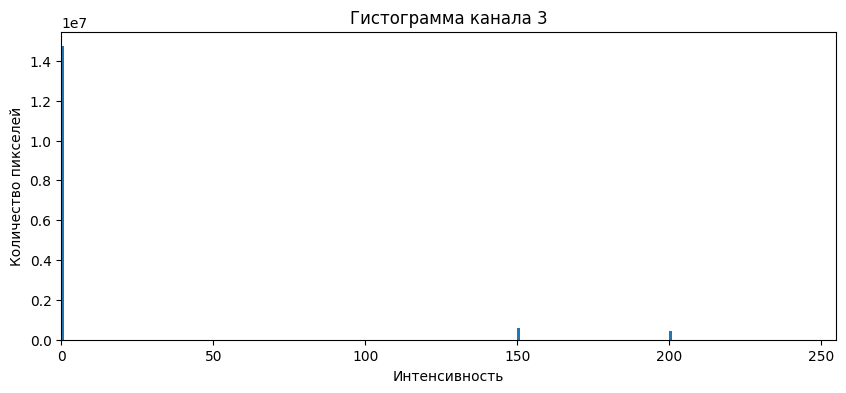

--- Канал 4 ---
Среднее значение уровня серого: 130.37
Минимум: 0
Максимум: 255


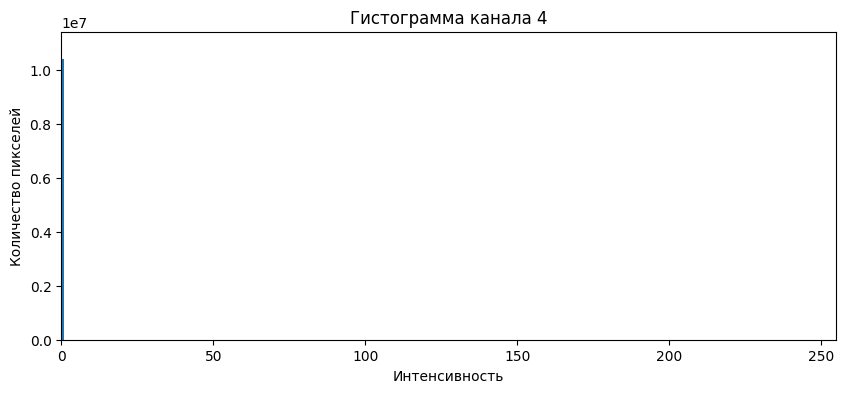

In [66]:
# Функция img2hist() из теоретических материалов (Тема 4, «Работа с гистограммами»)
def img2hist(temp_img, label=True):
    # Для цветного изображения анализируем яркостный канал Y.
    if temp_img.ndim == 3:
        values = cv.cvtColor(temp_img, cv.COLOR_BGR2YCrCb)[:, :, 0]
        channel_name = "Y"
    else:
        values = temp_img
        channel_name = "уровня серого"

    if label:
        print(f"Среднее значение {channel_name}: {values.mean():.2f}")
        print(f"Минимум: {values.min()}")
        print(f"Максимум: {values.max()}")

    plt.figure(figsize=(10, 4))
    plt.hist(values.ravel(), bins=256, range=(0, 256))
    plt.xlim([0, 255])
    plt.xlabel("Интенсивность")
    plt.ylabel("Количество пикселей")


# Изображение 4-канальное, поэтому строим гистограмму для каждого канала отдельно
for c in range(img.shape[2]):
    print(f"--- Канал {c + 1} ---")
    img2hist(img[:, :, c])
    plt.title(f"Гистограмма канала {c + 1}")
    plt.show()

#### **Пункт 4.3. Нормализация SAR-изображения**

Перевод в децибелы (dB) может быть полезным для ряда причин при обработке и анализе SAR изображений:

1. Нормализация: Перевод в децибелы может использоваться для нормализации значений яркостей на изображении. Такая нормализация позволяет визуально сравнивать яркости пикселей в разных областях изображения или разных изображениях.

2. Логарифмическая шкала: Децибелы предоставляют логарифмическую шкалу для оценки яркости сигналов. Логарифмическая шкала часто используется для измерения или анализа сигналов, так как она более чувствительна к изменениям в слабых сигналах и может помочь в выявлении слабых расположенных объектов.

3. Снижение динамического диапазона: Одним из преимуществ перевода в децибелы является снижение динамического диапазона значений яркости. Это может быть полезным при обработке и визуализации изображений, так как позволяет лучше выделить детали, особенности и структуры, которые могут быть затеряны в более широком динамическом диапазоне значений.

4. Чувствительность к изменениям: Перевод в децибелы позволяет лучше отслеживать и измерять изменения яркости. Изменения в яркости изображений в децибелах отражают более пропорциональные изменения в амплитуде сигнала, что может быть полезным, например, при обработке временных рядов или отслеживании изменений в рамках одного изображения.

**Переведите изображение в децибелы, используя следующую функцию:**

In [67]:
def img2dB(image_o, eps=1e-10):
    image = image_o.copy()
    dB = np.where(image > eps, image, -10)
    np.log10(dB, out=dB, where=dB > 0, casting='unsafe')
    return dB

**Напишите функцию img_to_uint(I), которая принимает на вход одномерный массив I и выполняет следующие действия:**

1. Находит минимальное значение (mn) и максимальное значение (mx) в массиве I.
2. Нормализует значения в массиве I, применяя следующую формулу: I = (I - mn) / (mx - mn).
3. Умножает результат на 255.
4. Возвращает массив I, приведенный к типу np.uint8. (Команда: I.astype(np.uint8))

Пример использования функции:



  ```python
  I = np.array([10, 20, 30, 40, 50])
  normalized_I = img_to_uint(I)
  print(normalized_I)
  ```

Результат:
  ```python
  array([0,  63, 127, 191, 255], dtype=uint8)
  ```

In [68]:
def img_to_uint(I):
    """Min-max нормализация массива в диапазон 0..255 и приведение к uint8."""
    I = np.asarray(I, dtype=np.float64)
    mn, mx = I.min(), I.max()          # 1. минимум и максимум
    if mx == mn:                       # защита от деления на ноль (все значения одинаковы)
        return np.zeros(I.shape, dtype=np.uint8)
    I = (I - mn) / (mx - mn)           # 2. нормализация в [0, 1]
    I = I * 255                        # 3. умножение на 255
    return I.astype(np.uint8)          # 4. приведение к uint8


I = np.array([10, 20, 30, 40, 50])
normalized_I = img_to_uint(I)
print(normalized_I)

[  0  63 127 191 255]


**Примените эту функцию к переведенному в децибелы изображению:**

После перевода в дБ: min = -10.000, max = 2.407
Канал 1: значения после нормализации -> [0, 253, 255]
Канал 2: значения после нормализации -> [0, 237, 246, 250, 253, 254, 255]
Канал 3: значения после нормализации -> [0, 250, 252, 253, 255]
Канал 4: значения после нормализации -> [0, 255]


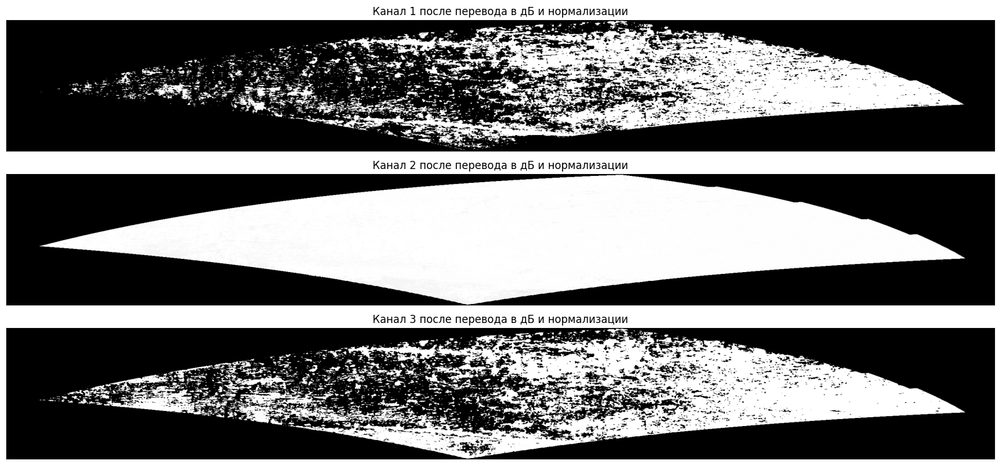

In [69]:
# img2dB работает с вещественными числами: для целочисленного uint16 np.where(..., -10)
# вызывает ошибку переполнения, а log10 записал бы результат в целый массив.
# Поэтому переводим изображение во float32 перед вызовом.
img_dB = img2dB(img.astype(np.float32))
print("После перевода в дБ: min = %.3f, max = %.3f" % (img_dB.min(), img_dB.max()))

# img_to_uint принимает одномерный массив, поэтому каждый канал «вытягиваем»
# в вектор (ravel), нормализуем и возвращаем исходную форму (reshape)
img_uint = np.zeros(img.shape, dtype=np.uint8)
for c in range(img.shape[2]):
    img_uint[:, :, c] = img_to_uint(img_dB[:, :, c].ravel()).reshape(img.shape[:2])

for c in range(img.shape[2]):
    print(f"Канал {c + 1}: значения после нормализации -> {np.unique(img_uint[:, :, c]).tolist()}")

fig, ax = plt.subplots(3, 1, figsize=(16, 7.5))
for c in range(3):
    ax[c].imshow(preview(img_uint[:, :, c]), cmap="gray", vmin=0, vmax=255, aspect="auto")
    ax[c].set_title(f"Канал {c + 1} после перевода в дБ и нормализации")
    ax[c].set_xticks([]); ax[c].set_yticks([])
plt.tight_layout()
plt.show()

**Вывод по пункту 4.3.** Функция `img2dB` заменяет нулевые значения на −10 (условный «логарифм» очень малой величины), а остальные — на их десятичный логарифм (≈ 1.5–2.4). Поэтому при min-max нормализации минимум задают именно нули (нет данных), и все реальные данные сжимаются в узкий диапазон **237–255**. Изображение выглядит почти однородно белым, а различия между классами почти не видны. Эту проблему решает следующий шаг — выравнивание гистограммы. (Строго говоря, децибелы — это $10 \cdot \log_{10}$; в задании используется заданная функция без множителя 10.)

#### **Пункт 4.4. Повышение контрастности изображения**

*В данном задании следует использовать изображение, полученное на предыдущем этапе (6.3).*

**Разбейте изображение на отдельные каналы:**



```
# Можно сделать так:

Channel_1 = image[:,:,0]
Channel_2 = image[:,:,1]
Channel_3 = image[:,:,2]
```



In [70]:
# Изображение, полученное на предыдущем этапе (в условии опечатка: «6.3» -> 4.3)
Channel_1 = img_uint[:, :, 0]
Channel_2 = img_uint[:, :, 1]
Channel_3 = img_uint[:, :, 2]
# 4-й канал — маска области съёмки (0/255), для повышения контраста он не нужен
valid_mask = img_uint[:, :, 3] > 0

for name, ch in (("Channel_1", Channel_1), ("Channel_2", Channel_2), ("Channel_3", Channel_3)):
    print(name, ch.shape, ch.dtype, "значения:", np.unique(ch).tolist())

Channel_1 (1422, 14958) uint8 значения: [0, 253, 255]
Channel_2 (1422, 14958) uint8 значения: [0, 237, 246, 250, 253, 254, 255]
Channel_3 (1422, 14958) uint8 значения: [0, 250, 252, 253, 255]


**С помощью методов для выравнивания гистограммы (адаптивного и не адаптивного), подберите оптимальные параметры контрастности отдельно для каждого канала, таким образом чтобы на них было видно как можно больше деталей и не было много шума:**

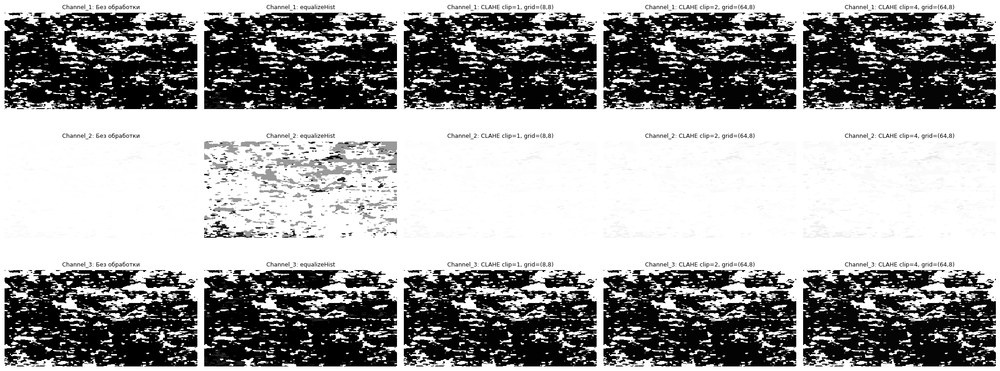

    Канал                     Метод  Уровней в области данных Диапазон
Channel_1             Без обработки                         3    0–255
Channel_1              equalizeHist                         3    0–255
Channel_1  CLAHE clip=1, grid=(8,8)                         3    2–255
Channel_1 CLAHE clip=2, grid=(64,8)                         6    2–255
Channel_1 CLAHE clip=4, grid=(64,8)                        10    2–255
Channel_2             Без обработки                         6  237–255
Channel_2              equalizeHist                         6    0–255
Channel_2  CLAHE clip=1, grid=(8,8)                        14  232–255
Channel_2 CLAHE clip=2, grid=(64,8)                        26  228–255
Channel_2 CLAHE clip=4, grid=(64,8)                        34  220–255
Channel_3             Без обработки                         5    0–255
Channel_3              equalizeHist                         5    0–255
Channel_3  CLAHE clip=1, grid=(8,8)                         8    2–255
Channe

In [71]:
# Сравниваем глобальное выравнивание (equalizeHist) и адаптивное (CLAHE)
# с разными параметрами. Для вытянутого изображения 14958 x 1422 сетка (8, 8)
# даёт сильно вытянутые плитки ~1870 x 178 px, поэтому пробуем и (64, 8) —
# почти квадратные плитки ~234 x 178 px.
variants = {
    "Без обработки": lambda ch: ch,
    "equalizeHist": lambda ch: cv.equalizeHist(ch),
    "CLAHE clip=1, grid=(8,8)": lambda ch: cv.createCLAHE(clipLimit=1.0, tileGridSize=(8, 8)).apply(ch),
    "CLAHE clip=2, grid=(64,8)": lambda ch: cv.createCLAHE(clipLimit=2.0, tileGridSize=(64, 8)).apply(ch),
    "CLAHE clip=4, grid=(64,8)": lambda ch: cv.createCLAHE(clipLimit=4.0, tileGridSize=(64, 8)).apply(ch),
}

y0, x0 = 300, 6000                              # фрагмент 1400 x 700 в центре полосы
frag = (slice(y0, y0 + 700), slice(x0, x0 + 1400))
channels = {"Channel_1": Channel_1, "Channel_2": Channel_2, "Channel_3": Channel_3}

rows = []
fig, ax = plt.subplots(3, len(variants), figsize=(22, 9))
for i, (ch_name, ch) in enumerate(channels.items()):
    for j, (v_name, func) in enumerate(variants.items()):
        res = func(ch)
        ax[i, j].imshow(res[frag], cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        ax[i, j].set_title(f"{ch_name}: {v_name}", fontsize=9)
        ax[i, j].axis("off")
        levels = np.unique(res[valid_mask])
        rows.append({"Канал": ch_name, "Метод": v_name, "Уровней в области данных": len(levels),
                     "Диапазон": f"{levels.min()}–{levels.max()}"})
plt.tight_layout()
plt.show()

print(pd.DataFrame(rows).to_string(index=False))

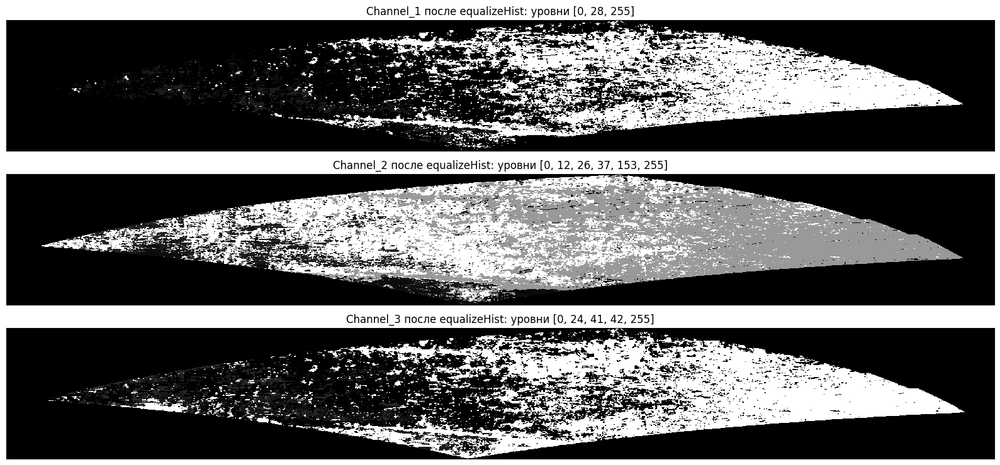

In [72]:
# Выбранные параметры: для всех трёх каналов — глобальное выравнивание гистограммы
Channel_1_eq = cv.equalizeHist(Channel_1)
Channel_2_eq = cv.equalizeHist(Channel_2)
Channel_3_eq = cv.equalizeHist(Channel_3)

fig, ax = plt.subplots(3, 1, figsize=(16, 7.5))
for a, ch, name in zip(ax, (Channel_1_eq, Channel_2_eq, Channel_3_eq), ("Channel_1", "Channel_2", "Channel_3")):
    a.imshow(preview(ch), cmap="gray", vmin=0, vmax=255, aspect="auto", interpolation="nearest")
    a.set_title(f"{name} после equalizeHist: уровни {np.unique(ch).tolist()}")
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout()
plt.show()

**Выбор параметров.** Для всех трёх каналов оптимальным оказалось **глобальное выравнивание `cv.equalizeHist()`**:
- После нормализации данные каждого канала занимают узкий диапазон (237–255). `equalizeHist` разносит эти дискретные уровни по всему диапазону 0–255, и границы между областями разных классов становятся хорошо видны. Особенно заметно это в канале 2: его 6 уровней превращаются в 0, 12, 26, 37, 153 и 255.
- CLAHE здесь работает хуже. При малом `clipLimit` (1–2) ограничение наклона не позволяет растянуть узкий диапазон: канал 2 остаётся почти белым, а почти бинарные каналы 1 и 3 не меняются. При увеличении `clipLimit` и числа плиток один и тот же класс в разных плитках получает разные значения: число уровней растёт с 3–6 до 10–34, хотя новой информации нет. Это и есть шум — ложные перепады на границах плиток. Адаптивный метод полезен для непрерывных снимков с неравномерной яркостью, а у нас кусочно-постоянная карта классов.
- Ограничение: из-за большой доли нулей (нет данных) редкие классы после `equalizeHist` получают тёмные значения (12–41). Они отличаются от фона численно, но визуально тёмные. Самый редкий уровень канала 2 (237, доли процента пикселей) получает значение 0 и сливается с фоном.

Объедините каналы в одно изображение, в качестве третьего канала используйте целочисленное частное первого и второго каналов, т.е.:



```
Channel_1 = Channel_1
Channel_1 = Channel_2
Channel_3 = int(Channel_1/Channel_2)
```







Значения третьего канала (частное): {0: 15673004, 1: 5597272}
Итоговое изображение: (1422, 14958, 3) uint8


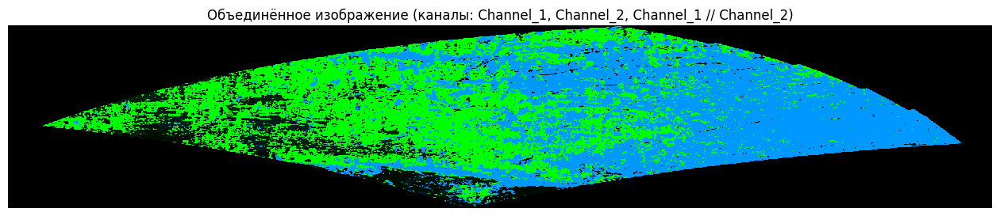

In [73]:
# Третий канал — целочисленное частное первого и второго каналов.
# Деление на ноль недопустимо, поэтому там, где Channel_2 = 0, записываем 0.
c1 = Channel_1_eq.astype(np.int32)
c2 = Channel_2_eq.astype(np.int32)
quotient = np.zeros_like(c1)
np.floor_divide(c1, c2, out=quotient, where=c2 > 0)
Channel_3_new = np.clip(quotient, 0, 255).astype(np.uint8)
print("Значения третьего канала (частное):", dict(zip(*[v.tolist() for v in np.unique(Channel_3_new, return_counts=True)])))

merged = cv.merge((Channel_1_eq, Channel_2_eq, Channel_3_new))
print("Итоговое изображение:", merged.shape, merged.dtype)

plt.figure(figsize=(16, 3))
plt.imshow(cv.cvtColor(preview(merged), cv.COLOR_BGR2RGB), aspect="auto", interpolation="nearest")
plt.title("Объединённое изображение (каналы: Channel_1, Channel_2, Channel_1 // Channel_2)")
plt.axis("off")
plt.show()

**Примечание.** После выравнивания значение первого канала нигде не превышает значение второго более чем вдвое. Поэтому целочисленное частное принимает только значения **0 и 1**: 1 там, где первый канал ненулевой, и 0 в остальных местах. Третий канал на изображении практически чёрный. Цвет итогового изображения определяют первые два канала. Канал собран строго по формуле из задания.

#### **Пункт 4.5. Сегментация изображения по цветовому диапазону**

Напишите функцию, которая принимает на вход **один канал** изображения и количество классов, после чего возвращает сегментированное изображение (маску)



Пример сегментации изображения (до и после):

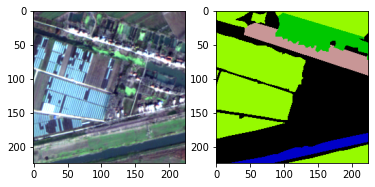

В Вашем случае сегментация происходит по следующим правилам:

1. Предположим, на вход функция получает изображение и число 4
2. Исходный диапазон (0, 255) делится на 4 промежутка: [0, 64), [64, 128), [128,192), [192,255]
3. Пиксели, интенсивность которых соответствует первому промежутку меняют свой цвет на красный, второму на черный, третьему на желтый, четвертому на зеленый (цвет Вы выбираете сами)
4.Получившаяся маска возвращается

Обратите внимание, что функция получает на вход один канал, а возвращать должна цветную маску(!), соответственно, у маски должно быть три канала. (Помним, что изображение это многомерный массив, в котором также можно замещать элементы с помощью перебора или математического аппарата numpy.)

**Сегментируйте первый канал изображения:**

Классы на градиенте: [(0, 0, 255), (0, 0, 255), (0, 0, 0), (0, 0, 0), (0, 255, 255), (0, 255, 255), (0, 255, 0), (0, 255, 0)]


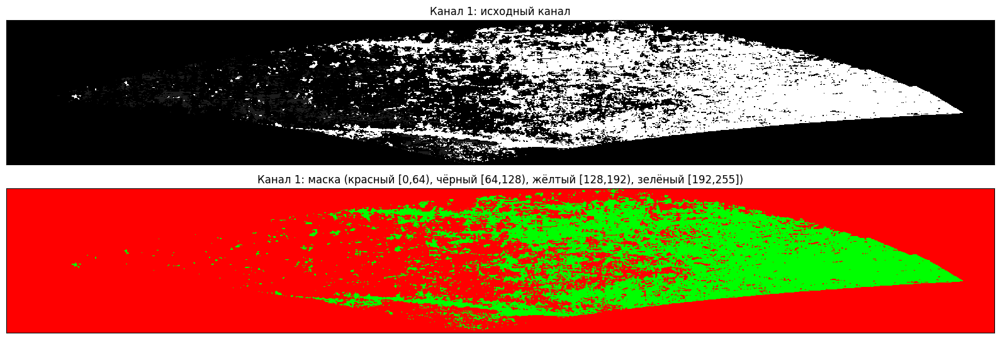

In [74]:
DEFAULT_COLORS = [(0, 0, 255),      # красный  (BGR)
                  (0, 0, 0),        # чёрный
                  (0, 255, 255),    # жёлтый
                  (0, 255, 0)]      # зелёный


def segment_channel(channel, n_classes, colors=None):
    """Сегментирует один канал по равным интервалам яркости и возвращает
    цветную (3-канальную) маску. Диапазон 0..255 делится на n_classes
    промежутков: для 4 классов — [0, 64), [64, 128), [128, 192), [192, 255]."""
    if not isinstance(channel, np.ndarray) or channel.ndim != 2:
        raise ValueError("Ожидается один канал изображения (двумерный массив).")
    if not isinstance(n_classes, (int, np.integer)) or not 1 <= n_classes <= 256:
        raise ValueError("n_classes должно быть целым числом от 1 до 256.")
    if colors is None:
        if n_classes <= len(DEFAULT_COLORS):
            colors = DEFAULT_COLORS[:n_classes]
        else:                                         # для большего числа классов — палитра
            hues = np.linspace(0, 179, n_classes, endpoint=False).astype(np.uint8)
            hsv = np.stack([hues, np.full_like(hues, 255), np.full_like(hues, 255)], -1)[None]
            colors = [tuple(int(v) for v in c) for c in cv.cvtColor(hsv, cv.COLOR_HSV2BGR)[0]]
    if len(colors) != n_classes:
        raise ValueError("Число цветов должно совпадать с числом классов.")

    # Номер класса каждого пикселя: значение * n // 256 (равные интервалы ширины 256/n)
    class_idx = (channel.astype(np.int32) * n_classes) // 256
    palette = np.array(colors, dtype=np.uint8)        # таблица «класс -> цвет»
    return palette[class_idx]                         # цветная маска (H, W, 3)


def show_segmentation(channel, mask, title):
    fig, ax = plt.subplots(2, 1, figsize=(16, 5.5))
    ax[0].imshow(preview(channel), cmap="gray", vmin=0, vmax=255, aspect="auto", interpolation="nearest")
    ax[0].set_title(f"{title}: исходный канал")
    ax[1].imshow(cv.cvtColor(preview(mask), cv.COLOR_BGR2RGB), aspect="auto", interpolation="nearest")
    ax[1].set_title(f"{title}: маска (красный [0,64), чёрный [64,128), жёлтый [128,192), зелёный [192,255])")
    for a in ax:
        a.set_xticks([]); a.set_yticks([])
    plt.tight_layout()
    plt.show()


# Проверка на градиенте 0..255: должны получиться 4 полосы равной ширины
test = np.tile(np.arange(256, dtype=np.uint8), (20, 1))
print("Классы на градиенте:", [tuple(int(v) for v in segment_channel(test, 4)[0, x]) for x in (0, 63, 64, 127, 128, 191, 192, 255)])

mask_1 = segment_channel(merged[:, :, 0], 4)
show_segmentation(merged[:, :, 0], mask_1, "Канал 1")

**Сегментируйте второй канал изображения:**

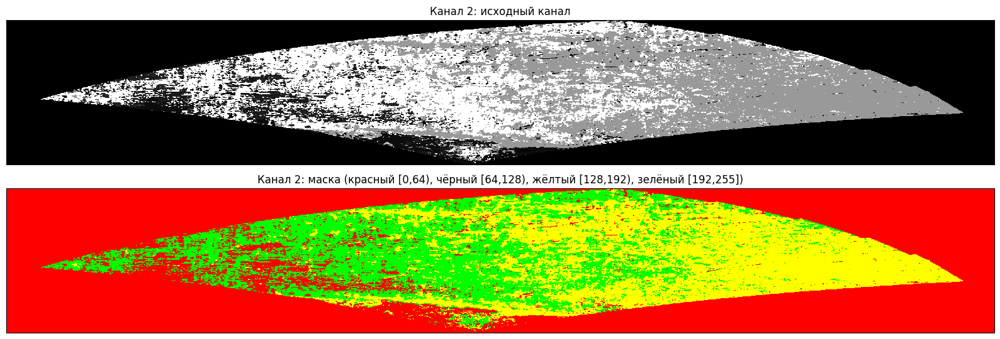

In [75]:
mask_2 = segment_channel(merged[:, :, 1], 4)
show_segmentation(merged[:, :, 1], mask_2, "Канал 2")

**Сегментируйте третий канал изображения:**

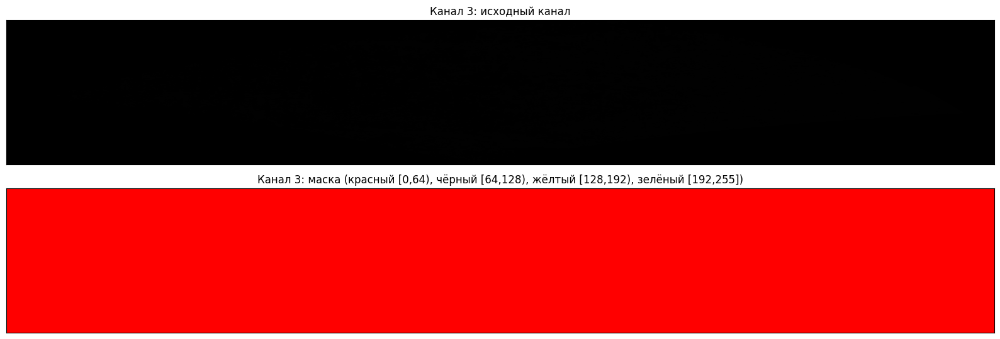

In [76]:
mask_3 = segment_channel(merged[:, :, 2], 4)
show_segmentation(merged[:, :, 2], mask_3, "Канал 3")

**Вывод по сегментации.** Канал 1 содержит значения 0, 28 и 255, поэтому получается два класса: красный (нет данных и редкий класс со значением 28) и зелёный. Канал 2 даёт три класса — красный, жёлтый (153) и зелёный (255) — и передаёт больше всего структуры. Канал 3 (частное 0/1) целиком попадает в первый промежуток [0, 64) и окрашивается в красный. Поэтому для разбиения на патчи используется **маска канала 2** как самая информативная.

#### **Пункт 4.7. Напишите функцию, которая получает на вход изображение и разделяет его на фрагменты (патчи), размером 256 на 256 пикселей. Функция должна вернуть массив из фрагментов.**








Алгоритм обрезки изображения на равные патчи можно реализовать следующим образом:

1. Получить размеры изображения (ширина и высота).
2. Задать размеры патча (например, ширина и высота патча равная 256 пикселей).
3. Вычислить количество патчей по горизонтали и вертикали, разделив размеры изображения на размеры патча и округлив результаты.
4. Создать пустой массив, в котором будут храниться обрезанные патчи.
5. Проходя по всем патчам, вырезать каждый патч из исходного изображения, используя размеры патча и текущие координаты.
6. Добавить вырезанный патч в массив патчей.
7. Вернуть массив патчей как результат работы алгоритма.

> Пример:
>
> Задание удобно выполнить с помощью срезов.
>
> Поскольку все изображения имеют разный размер, нам необходимо обрезать исходное изображение до ближайшего размера, кратного 256,
>
> Исходная размерность: (1920, 1080, 3)
>
> X = 1920 // 256 = 7 (количество фрагментов по горизонтали)
>
> Y = 1080 // 256 = 4 (количество фрагментов по вертикали)
>
> X = 256 * 7 = 1792
>
> Y = 256 * 4 = 1024
>
> Размерность после обрезки: (1792, 1024, 3)
>
> После этого итеративно проходимся по изображению (можно двумя циклами - по вертикали и по горизонтали) и помещаем в массив обрезанные фрагменты.

**Разделите на патчи изображение:**

In [77]:
def split_into_patches(image, patch_size=256):
    """Разбивает изображение на фрагменты patch_size x patch_size.
    Изображение предварительно обрезается до размеров, кратных patch_size.
    Возвращает массив формы (N, patch_size, patch_size[, каналы])."""
    if not isinstance(image, np.ndarray) or image.ndim not in (2, 3):
        raise ValueError("Ожидается изображение — массив NumPy (H, W) или (H, W, C).")
    h, w = image.shape[:2]                               # 1. размеры изображения
    ny, nx = h // patch_size, w // patch_size            # 3. число патчей по вертикали и горизонтали
    if ny == 0 or nx == 0:
        raise ValueError("Изображение меньше размера одного патча.")
    cropped = image[:ny * patch_size, :nx * patch_size]  # обрезка до кратного размера

    patches = []                                         # 4. массив для патчей
    for i in range(ny):                                  # 5. проход по вертикали
        for j in range(nx):                              #    и по горизонтали
            patch = cropped[i * patch_size:(i + 1) * patch_size,
                            j * patch_size:(j + 1) * patch_size]
            patches.append(patch)                        # 6. добавляем патч
    return np.array(patches)                             # 7. результат


img_patches = split_into_patches(merged)
print(f"Исходный размер: {merged.shape}, после обрезки: "
      f"{(merged.shape[0] // 256) * 256} x {(merged.shape[1] // 256) * 256}")
print("Патчи изображения:", img_patches.shape, img_patches.dtype)

Исходный размер: (1422, 14958, 3), после обрезки: 1280 x 14848
Патчи изображения: (290, 256, 256, 3) uint8


**Разделите на патчи сегментированную маску:**

In [78]:
mask_patches = split_into_patches(mask_2)
print("Патчи маски:", mask_patches.shape, mask_patches.dtype)

Патчи маски: (290, 256, 256, 3) uint8


**После этого сохраните получившиеся массивы в файлы img.npy и mask.npy:**

[Документация Numpy](https://numpy.org/doc/stable/reference/generated/numpy.save.html)



##### **Пример сохранения массива в файл:**



```python
import numpy as np

x = np.arange(10)
print(x)
np.save("outfile.npy", x)
```
```
[0 1 2 3 4 5 6 7 8 9]
```


##### **Пример загрузки массива из файла:**

```python
import numpy as np

x = np.arange(10)
print(x)
np.save("outfile.npy", x)
```
```
[0 1 2 3 4 5 6 7 8 9]
```

In [79]:
np.save("img.npy", img_patches)
np.save("mask.npy", mask_patches)

# Проверка: загружаем обратно и сравниваем
img_loaded = np.load("img.npy")
mask_loaded = np.load("mask.npy")
print("img.npy:", img_loaded.shape, "| совпадает с исходным:", np.array_equal(img_loaded, img_patches))
print("mask.npy:", mask_loaded.shape, "| совпадает с исходным:", np.array_equal(mask_loaded, mask_patches))

img.npy: (290, 256, 256, 3) | совпадает с исходным: True
mask.npy: (290, 256, 256, 3) | совпадает с исходным: True


**Отобразите, используя matplotlib, 10 случайных элементов патчей растра и маски с одинаковыми индексами (должны соответствовать):**

Патчей с данными: 194 из 290


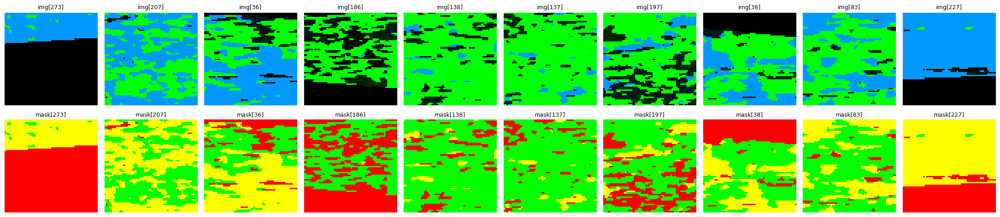

In [80]:
rng = np.random.default_rng(42)

# Около трети патчей целиком лежат вне полосы съёмки (только нули),
# поэтому случайные индексы выбираем среди патчей, где есть данные
has_data = np.array([np.count_nonzero(p) > 0.1 * p.size for p in img_loaded])
candidates = np.flatnonzero(has_data)
print(f"Патчей с данными: {len(candidates)} из {len(img_loaded)}")
indices = rng.choice(candidates, size=10, replace=False)

fig, ax = plt.subplots(2, 10, figsize=(22, 5))
for k, idx in enumerate(indices):
    ax[0, k].imshow(cv.cvtColor(img_loaded[idx], cv.COLOR_BGR2RGB), interpolation="nearest")
    ax[0, k].set_title(f"img[{idx}]", fontsize=9)
    ax[1, k].imshow(cv.cvtColor(mask_loaded[idx], cv.COLOR_BGR2RGB), interpolation="nearest")
    ax[1, k].set_title(f"mask[{idx}]", fontsize=9)
    ax[0, k].axis("off"); ax[1, k].axis("off")
plt.tight_layout()
plt.show()